---
title: Chapter 1 · Introduction to Nanosensors
---

<div style="border-left:7px solid #1f4e79; padding:2px 0 2px 20px; margin:14px 0 8px 0;">
<span style="letter-spacing:3.5px; font-size:0.78em; color:#1f4e79; font-weight:700;">NANOSENSORS &middot; FROM SINGLE MOLECULES TO SMART DEVICES</span>
<h1 style="margin:8px 0 4px 0; font-size:2.25em; line-height:1.15; color:#152238;">Chapter 1 &middot; Introduction to Nanosensors</h1>
<div style="font-size:1.12em; color:#44546a; font-style:italic;">How we turn the physical world into data, and why the nanoscale changes the rules</div>
</div>

**An interactive open-book chapter.** The text is meant to be read, the code cells are meant to be played with, and the sliders are meant to be pushed. Nothing here is a black box: every model in this chapter is a few lines of Python that you can inspect and change.

### About this chapter

Chapter 1 has one job: to build the conceptual toolkit that every later chapter assumes. Before we can talk about a nanopore that reads DNA base by base, or a gold nanoparticle that changes colour when a toxin appears, we need a shared language for what a sensor *is*, what it is *not*, and how we judge whether it is any good.

The first half of the chapter is deliberately sensor-agnostic. It covers the anatomy of a measurement, the difference between chemical and physical sensing, and the metrics that decide whether a measurement is trustworthy: sensitivity, limit of detection, selectivity, accuracy and precision. The second half walks down the size scale, explains what changes when a sensing element becomes smaller than about 100 nanometres, and introduces the nanomaterial platforms that the rest of the book is built on.

> **How to use this chapter (and this book)**
>
> - **Run the cells in order.** The first code cell imports the libraries and defines a few helpers that later cells rely on. `Kernel > Restart & Run All` is the most reliable way to read the notebook.
> - **Interact.** Cells marked **Try it** contain sliders. Change *one* parameter at a time and read the diagnostic box: it tells you what the change did and which limit you are hitting.
> - **Don't trust the formulae blindly.** Each model is a teaching model, deliberately simplified. Where the simplification matters, the text says so.
> - **No prior Python needed.** If you can move a slider, you can do the exercises. If you want to learn, open a code cell, change a number, and re-run it.

*Reading time: about 60&ndash;90 minutes including the interactive sections.*

**You will need:** a live Jupyter kernel with `numpy`, `matplotlib` and `ipywidgets`. The setup cell checks this for you.

In [1]:
# =============================================================================
#  Chapter 1 - environment setup.  Run this cell first.
# =============================================================================
import os, sys, math, tempfile
os.environ.setdefault("MPLCONFIGDIR", os.path.join(tempfile.gettempdir(), "mplconfig-nanosensors"))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import (FancyBboxPatch, FancyArrowPatch, Circle,
                                Rectangle, Polygon, Ellipse, Wedge, Arc,
                                RegularPolygon)
from matplotlib.lines import Line2D

import ipywidgets as widgets
from ipywidgets import (interact, interactive_output, FloatSlider, IntSlider,
                        Dropdown, Layout, HBox, VBox, Label, HTML)

# ---------------------------------------------------------------- house style
PALETTE = dict(
    blue="#1f4e79", teal="#2a9d8f", gold="#e9c46a", coral="#e76f51",
    ink="#22333b", gray="#6c757d", paper="#f4f8fb", red="#c1121f",
    green="#2a9d8f", violet="#6a4c93", sky="#4a90c2",
)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "font.family": "DejaVu Sans",
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.titlepad": 10,
    "axes.labelsize": 11,
    "axes.edgecolor": "#3d4a55",
    "axes.linewidth": 0.9,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "grid.linestyle": "-",
    "legend.fontsize": 9,
    "legend.frameon": False,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "figure.autolayout": False,
})

def style_axes(ax, grid=True):
    '''Consistent, quietly styled axes: no top/right spines.'''
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(grid, alpha=0.22)
    return ax

# ---------------------------------------------------------------- saving figs
FIG_DIR = "figures"
SAVE_FIGURES = True          # set to False to keep the notebook side-effect free

def save_fig(fig, name):
    '''Save a figure next to the notebook so it can be reused in the HTML/PDF build.'''
    if not SAVE_FIGURES:
        return
    try:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200, bbox_inches="tight")
    except Exception as exc:                                    # pragma: no cover
        print(f"[note] could not save {name}.png: {exc}")

# ---------------------------------------------------------------- helpers
def wavelength_to_rgb(wavelength, gamma=0.8):
    '''Approximate RGB colour for a wavelength in nm (380-780).'''
    wl = float(np.clip(wavelength, 380, 780))
    if wl < 440:
        r, g, b = -(wl - 440) / 60, 0.0, 1.0
    elif wl < 490:
        r, g, b = 0.0, (wl - 440) / 50, 1.0
    elif wl < 510:
        r, g, b = 0.0, 1.0, -(wl - 510) / 20
    elif wl < 580:
        r, g, b = (wl - 510) / 70, 1.0, 0.0
    elif wl < 645:
        r, g, b = 1.0, -(wl - 645) / 65, 0.0
    else:
        r, g, b = 1.0, 0.0, 0.0
    if wl > 700:
        f = 0.35 + 0.65 * (780 - wl) / 80
    elif wl < 420:
        f = 0.35 + 0.65 * (wl - 380) / 40
    else:
        f = 1.0
    return tuple(np.clip(np.array([r, g, b]) * f, 0, 1) ** gamma)

def blend(c1, c2, t):
    '''Linear blend between two RGB colours; t=0 gives c1, t=1 gives c2.'''
    return tuple(np.clip(np.array(c1) * (1 - t) + np.array(c2) * t, 0, 1))

def diagnostic_box(fig, text, y=0.015, fontsize=9.6):
    '''A rounded diagnostic read-out under a figure.'''
    fig.text(0.5, y, text, ha="center", va="bottom", fontsize=fontsize,
             family="DejaVu Sans", linespacing=1.35,
             bbox=dict(boxstyle="round,pad=0.55", facecolor="white",
                       edgecolor="#b8c4d0", linewidth=1.0))

# ---------------------------------------------------------------- versions
print(f"Python            {sys.version.split()[0]}")
print(f"numpy             {np.__version__}")
print(f"matplotlib        {matplotlib.__version__}")
print(f"ipywidgets        {widgets.__version__}")
print("Environment ready. Interactive figures below run in this kernel.")

Matplotlib is building the font cache; this may take a moment.


Python            3.13.13
numpy             2.4.6
matplotlib        3.10.9
ipywidgets        8.1.7
Environment ready. Interactive figures below run in this kernel.


### Learning objectives

By the end of this chapter you should be able to:

1. **Distinguish** a sensor, a transducer and a device, and describe the stages of a measurement chain.
2. **Classify** sensors as chemical or physical, and explain why the boundary is often blurry.
3. **Define and interpret** sensitivity, limit of detection, dynamic range, selectivity, accuracy and precision, and explain how they trade off against each other.
4. **Explain** why measurements matter outside the laboratory: exploration, environmental monitoring, artificial intelligence and public health.
5. **Describe** what makes a sensor a *nanosensor*, including surface-to-volume scaling, quantum confinement and single-molecule detection.
6. **Identify** the main nanomaterial platforms and transduction mechanisms used in nanosensing.
7. **Evaluate** nanosensors critically: what they gain at the nanoscale, and what they pay for it.

### Roadmap

| Section | The question it answers |
|---|---|
| **1. Sensor vs. device** | What is actually doing the measuring? |
| **2. Chemical vs. physical sensors** | What kind of stimulus is being transduced? |
| **3. Metrics of performance** | How do we know whether a sensor is any good? |
| **4. Why do we need sensors?** | What do sensors let civilisation do? |
| **5. Sensors in disease control** | What happens when sensing arrives too late? |
| **6. Enter the nanoscale** | What changes when the sensor is 100&nbsp;nm wide? |
| &mdash; | **Summary &amp; self-check** | Did it stick? |

### Interactive elements at a glance

| # | Section | What you can play with | What to look for |
|---|---|---|---|
| 1 | 1 | Measurement chain: signal, noise, ADC bits | How the *device* limits the *sensor* |
| 2 | 2 | pH indicator: a chemical sensor changing colour | A molecular state becoming an optical signal |
| 3 | 2 | FRET: a molecular ruler from 1 to 15&nbsp;nm | Distance turning into colour |
| 4 | 3 | Calibration curve: sensitivity, LoD, saturation | The three zones every sensor has |
| 5 | 3 | Selectivity: target + interferent | How cross-talk destroys accuracy |
| 6 | 3 | Accuracy vs. precision dartboard | Bias and scatter are different problems |
| 7 | 5 | Outbreak + diagnostics | Why early detection flattens a curve |
| 8 | 6 | Surface-to-volume ratio at the nanoscale | Why small is surface-dominated |
| 9 | 6 | Quantum-dot colour vs. size | Quantum confinement you can see |

*Section 4.3 is a reading case study rather than a widget.*



## Prologue: from chaos to data

Look around you. The room you are in is a storm of physical and chemical information: photons of many wavelengths, pressure waves, temperature gradients, and a soup of molecules drifting through the air. Your body is already measuring all of it, continuously, cheaply, and mostly without your permission.

Almost every modern technology rests on the same trick: **converting the analogue chaos of the real world into structured, understandable data.** The smartphone in your pocket counts the steps you take because a microscopic silicon structure bends when you accelerate. The weather model that decides whether you need an umbrella is fed by thousands of thermometers, barometers and satellites. The PCR test that told you whether you had a virus was, at heart, a simple chemical sensor.

This book is about the tools that make that conversion possible, and about what happens when those tools are shrunk to the scale of single molecules. But before we can appreciate a sensor that detects one molecule in a litre of water, we need to be precise about the basics. That is the job of this first chapter.

> **The central question of Chapter 1**
>
> A sensor is not a magic box that "measures". It is a chain of physical processes: recognition, transduction, amplification, digitisation and interpretation. The measurement is only as trustworthy as the weakest link in that chain. Everything that follows in this book is an attempt to shorten that chain, make it more sensitive, or make it more selective.

The first half of the chapter stays deliberately general. We start with the oldest sensor array in existence (your own body), then formalise the difference between a sensor and a device, classify sensors by the kind of stimulus they detect, and define the metrics by which any sensor is judged, whether a &euro;10 thermometer or a &euro;100,000 nanopore sequencer.

In the second half we go small. We will see that shrinking a sensor below roughly 100 nanometres is not simply a matter of miniaturisation. At that scale, the rules change: surfaces dominate volumes, electrons become confined, diffusion becomes fast, and a sensor can begin to count individual molecules. That is the regime where nanosensors live, and it is where the rest of this book is set.



## 1. What is a sensor, and what is a device?

### 1.1 The hardware of perception

To understand the difference between a sensor and a device, we do not need to look any further than our own bodies.

Your **eyes, ears, nose, tongue and skin are sensors.** They sit at the boundary between you and the world, exposed to the environment, and each one is tuned to a particular kind of stimulus: photons, pressure waves, volatile molecules, dissolved chemicals, temperature and touch. A sensor's job is simple but profound: it *senses a stimulus and changes state*, converting that stimulus into a signal. In the body, that signal is an electrical impulse travelling along a nerve.

Your **brain is the device.** An eye that registers light is useless without something to interpret that light as an approaching car. The device takes the raw signal from the sensor and processes, analyses and translates it into actionable understanding. It compares, remembers, filters, predicts and, crucially, decides.

The same division of labour appears in every measurement instrument ever built. In technology, a **sensor** is the element that directly interacts with a physical or chemical variable to produce a measurable output: a change in colour, intensity, voltage, current or frequency. The **device** is the overarching system: the electronics, microcontroller, display, fluidics and software that reads that output and tells us what actually happened.

### 1.2 Three words that are often confused

- **Sensor.** The element (or small assembly) that responds to a stimulus. It is the part that "touches" the world.
- **Transducer.** The physical mechanism that converts one form of energy into another. Every sensor contains at least one transducer; sometimes the words are used interchangeably, but strictly the transducer is the *conversion engine*, while the sensor is the *functional element* that includes whatever makes it selective.
- **Device / instrument.** The complete system that powers, reads, digitises, calibrates, displays and communicates the sensor's output.

A useful rule of thumb: **if it needs a battery, a screen or a data cable, it is a device, not just a sensor.** A thermistor is a sensor. A digital thermometer is a device. A thermistor inside a digital thermometer is still a sensor, and its accuracy depends on both the thermistor and the electronics that read it.

### 1.3 The measurement chain

Every measurement, from a kitchen thermometer to a single-molecule nanopore sequencer, can be decomposed into the same sequence of stages. Figure 1.1 shows the chain in its most general form.

A stimulus (the thing we care about) is recognised by a **recognition element** (a receptor, a selective membrane, a dye, an antibody, a nanoscale pore). The recognition event is converted by a **transducer** into a measurable signal, usually electrical or optical. That signal is then conditioned, amplified, filtered, sometimes compared against a reference, and digitised by an **analogue-to-digital converter (ADC)**. Finally the device **processes** the numbers: it applies the calibration curve, corrects for drift, averages, and turns the result into a number on a screen, a colour on a test strip, or a decision to close a border.

*Figure 1.1 is generated by the code cell below.*

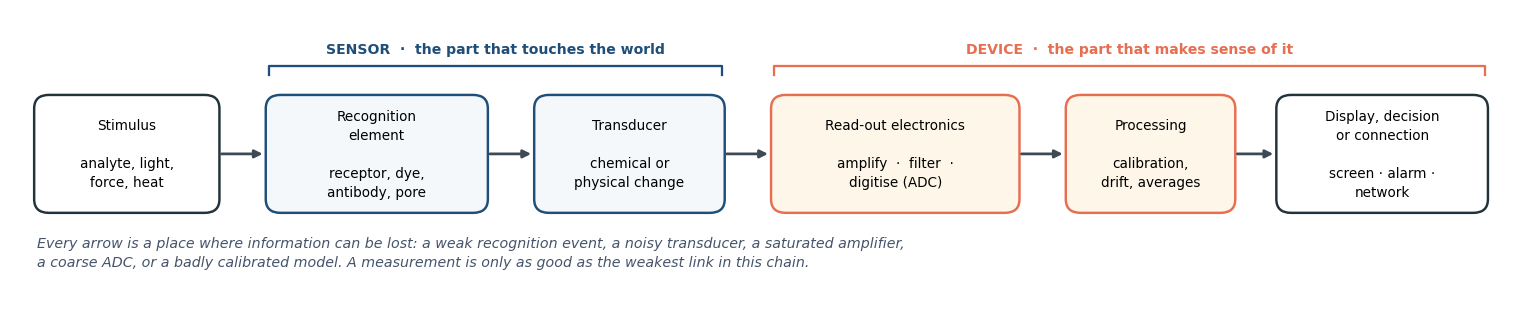

In [2]:
fig, ax = plt.subplots(figsize=(14.0, 3.15))
ax.set_xlim(0, 14.3)
ax.set_ylim(0.15, 3.35)
ax.axis("off")

boxes = [
    (0.25, 1.30, 1.70, 1.15, "Stimulus\n\nanalyte, light,\nforce, heat", "#ffffff", PALETTE["ink"]),
    (2.45, 1.30, 2.05, 1.15, "Recognition\nelement\n\nreceptor, dye,\nantibody, pore", PALETTE["paper"], PALETTE["blue"]),
    (5.00, 1.30, 1.75, 1.15, "Transducer\n\nchemical or\nphysical change", PALETTE["paper"], PALETTE["blue"]),
    (7.25, 1.30, 2.30, 1.15, "Read-out electronics\n\namplify  ·  filter  ·\ndigitise (ADC)", "#fdf6e9", PALETTE["coral"]),
    (10.05, 1.30, 1.55, 1.15, "Processing\n\ncalibration,\ndrift, averages", "#fdf6e9", PALETTE["coral"]),
    (12.05, 1.30, 1.95, 1.15, "Display, decision\nor connection\n\nscreen · alarm ·\nnetwork", "#ffffff", PALETTE["ink"]),
]

for x, y, w, h, label, face, edge in boxes:
    box = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.14",
                         linewidth=1.6, edgecolor=edge, facecolor=face, zorder=2)
    ax.add_patch(box)
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center",
            fontsize=8.9, zorder=3, linespacing=1.45)

arrow_kw = dict(arrowstyle="-|>", mutation_scale=17, linewidth=1.8)
for x0, x1 in [(1.97, 2.42), (4.52, 4.97), (6.77, 7.22), (9.57, 10.02), (11.62, 12.02)]:
    ax.annotate("", xy=(x1, 1.875), xytext=(x0, 1.875),
                arrowprops=dict(arrowstyle="-|>", color="#3d4a55", lw=1.8), zorder=4)

# scope brackets
def bracket(x0, x1, y, label, color):
    ax.plot([x0, x0, x1, x1], [y - 0.10, y, y, y - 0.10], color=color, lw=1.5, clip_on=False)
    ax.text((x0 + x1) / 2, y + 0.10, label, ha="center", va="bottom",
            fontsize=9.2, color=color, fontweight="bold")

bracket(2.45, 6.75, 2.78, "SENSOR  ·  the part that touches the world", PALETTE["blue"])
bracket(7.25, 14.00, 2.78, "DEVICE  ·  the part that makes sense of it", PALETTE["coral"])

ax.text(0.25, 0.72,
        "Every arrow is a place where information can be lost: a weak recognition event, a noisy transducer, a saturated amplifier,\n"
        "a coarse ADC, or a badly calibrated model. A measurement is only as good as the weakest link in this chain.",
        fontsize=9.3, color="#44546a", style="italic", linespacing=1.5)

fig.tight_layout()
save_fig(fig, "fig_1_1_measurement_chain")
plt.show()

<p style="text-align:center; font-size:0.92em; color:#555; margin-top:-6px;">
<b>Figure 1.1: The measurement chain.</b> A sensor (blue) converts a stimulus into a signal; a device (orange) conditions, digitises and interprets that signal. The same six-stage architecture underlies a &euro;5 thermometer and a &euro;100,000 single-molecule sequencer. The real differences lie in <i>which</i> stage limits performance.
</p>

The chain is a useful diagnostic tool. When a measurement is bad, the question is never simply "the sensor is bad". It might be that the recognition element is not selective, the transducer is noisy, the amplifier is saturated, the ADC is too coarse, or the calibration model is wrong. Later in this chapter you will deliberately break each link in turn and watch the measurement fail.

**A worked example: the smartphone step counter.** The sensor is a MEMS accelerometer, a tiny silicon proof mass that moves when the phone accelerates, changing a capacitance. The transducer is capacitive: acceleration becomes a voltage. The device amplifies and digitises that voltage, runs a filtering and peak-detection algorithm, and turns three orthogonal acceleration traces into "8,412 steps today". The accelerometer is a superb sensor, but it cannot tell walking from driving from a bumpy bus ride on its own. That distinction lives in the device's processing, and it is only as good as the data the sensor supplies.

### 1.4 Sensor vs. device: a summary

| | **Sensor** | **Device / instrument** |
|---|---|---|
| **What it is** | The element that interacts with the stimulus | The complete measurement system around it |
| **Job** | Recognise and transduce | Power, read, digitise, process, display, communicate |
| **Typical examples** | Thermistor, photodiode, pH dye, antibody, nanopore, nanowire | Digital thermometer, smartphone, glucometer, sequencer, weather station |
| **Output** | An analogue signal (resistance, voltage, colour, current) | A number, a decision, an alarm, a data stream |
| **Limits it imposes** | Selectivity, sensitivity, drift, noise | Resolution, calibration, speed, cost, power, connectivity |
| **Fails when** | The stimulus is not recognised or transduced | The signal is misread, mis-calibrated or misinterpreted |

The distinction matters because the two parts of the system fail in different ways, and they must be designed together. A brilliant sensor attached to a careless device gives careless measurements. Conversely, a cheap sensor with excellent electronics and calibration can outperform an expensive sensor with a poor read-out chain, a theme we will return to repeatedly.

### 1.5 Try it: from stimulus to number

The widget below builds a simplified measurement chain in silico. A "glucose" concentration is converted to a voltage by a sensor with a given **sensitivity**; random **noise** is added (this is the physical limit of the transducer); an **ADC** with a chosen number of bits digitises the voltage; and the device reports a concentration by inverting the calibration.

Set the parameters and watch the two panels. The left panel is what an oscilloscope would see; the right panel is what the device's software would report if the same sample were measured 2,000 times.

In [3]:
def measurement_chain_demo(true_value=100, sensitivity=1.2, noise_sigma=1.0, adc_bits=10):
    '''From a physical quantity to the number a device reports.'''
    rng = np.random.default_rng(7)

    offset = 20.0          # mV: zero-concentration offset of the electronics
    v_ref = 500.0          # mV: ADC full-scale range
    n_levels = 2 ** adc_bits
    lsb = v_ref / n_levels  # mV per ADC step

    v_ideal = offset + sensitivity * true_value

    # --- a short oscilloscope trace -----------------------------------------
    n_trace = 24
    idx = np.arange(1, n_trace + 1)
    v_analog = v_ideal + rng.normal(0.0, noise_sigma, n_trace)
    v_digital = np.round(v_analog / lsb) * lsb

    # --- 2000 repeat measurements of the same sample ------------------------
    v_many = v_ideal + rng.normal(0.0, noise_sigma, 2000)
    v_many_d = np.round(v_many / lsb) * lsb
    conc = (v_many_d - offset) / sensitivity

    res_conc = lsb / sensitivity          # resolution floor imposed by the ADC
    noise_conc = noise_sigma / sensitivity  # resolution floor imposed by noise
    bias = conc.mean() - true_value
    scatter = conc.std()
    rmse = np.sqrt(np.mean((conc - true_value) ** 2))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 5.35))

    # ---------------------------------------------------------------- left
    ax1.plot(idx, v_analog, "o", ms=5.5, color=PALETTE["coral"],
             label="analogue signal (transducer + noise)", zorder=3)
    ax1.step(idx, v_digital, where="mid", color=PALETTE["blue"], lw=2.0,
             label="digitised steps (after ADC)", zorder=2)
    ax1.axhline(v_ideal, color=PALETTE["gold"], lw=2.4, ls="--",
                label=f"ideal value = {v_ideal:.1f} mV", zorder=1)
    ax1.set_xlabel("repeated reading #")
    ax1.set_ylabel("sensor output (mV)")
    ax1.set_title("1 · Sensor + electronics: the analogue signal")
    ax1.set_xlim(0.5, n_trace + 0.5)
    y_lo = float(min(v_analog.min(), v_digital.min(), v_ideal))
    y_hi = float(max(v_analog.max(), v_digital.max(), v_ideal))
    span = max(y_hi - y_lo, 1.0)
    ax1.set_ylim(y_lo - 0.18 * span, y_hi + 0.95 * span)
    ax1.legend(loc="upper left", fontsize=8.1, frameon=True, framealpha=0.92,
               edgecolor="#cfd8e0")
    style_axes(ax1)
    ax1.text(0.985, 0.965,
             f"ADC step (LSB) = {lsb:.3f} mV\n= {res_conc:.3f} mg/dL",
             transform=ax1.transAxes, ha="right", va="top", fontsize=8.4,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                       edgecolor="#b8c4d0", alpha=0.95))

    # ---------------------------------------------------------------- right
    ax2.hist(conc, bins=60, color=PALETTE["blue"], alpha=0.75,
             edgecolor="white", linewidth=0.4)
    ax2.axvline(true_value, color=PALETTE["gold"], lw=2.6, ls="--",
                label=f"true value = {true_value} mg/dL")
    ax2.axvline(conc.mean(), color=PALETTE["coral"], lw=2.0,
                label=f"reported mean = {conc.mean():.1f} mg/dL")
    ax2.set_xlabel("reported concentration (mg/dL)")
    ax2.set_ylabel("number of readings")
    ax2.set_title("2 · Device: what gets reported (2,000 repeats)")
    ax2.legend(loc="upper right", fontsize=8.4)
    style_axes(ax2)

    # which limit dominates?
    if noise_sigma == 0:
        limiter = "noise is zero: resolution is limited only by the ADC"
    elif res_conc > 2.0 * noise_conc:
        limiter = "the ADC is too coarse  →  add bits"
    elif noise_conc > 2.0 * res_conc:
        limiter = "the sensor noise dominates  →  average or cool the electronics"
    else:
        limiter = "ADC resolution and sensor noise are comparable"

    if rmse < 2.0:
        verdict = "excellent agreement with the true value"
    elif rmse < 8.0:
        verdict = "usable, but the error is visible"
    else:
        verdict = "not fit for a quantitative measurement"

    diag = (
        "--- Measurement-chain diagnostics ---\n"
        f"Sensitivity: {sensitivity:.2f} mV per mg/dL      "
        f"ADC: {adc_bits} bits  ({n_levels:,} levels over {v_ref:.0f} mV)\n"
        f"Resolution floor from ADC: {res_conc:.2f} mg/dL      "
        f"Resolution floor from noise: {noise_conc:.2f} mg/dL\n"
        f"Systematic bias: {bias:+.2f} mg/dL      Scatter (precision): {scatter:.2f} mg/dL      RMSE: {rmse:.2f} mg/dL\n"
        f"Limiting stage: {limiter}\n"
        f"Verdict: {verdict}"
    )
    fig.tight_layout(rect=(0, 0.245, 1, 1))
    diagnostic_box(fig, diag, y=0.010, fontsize=9.0)
    save_fig(fig, "int_1_measurement_chain")
    plt.show()

interact(
    measurement_chain_demo,
    true_value=IntSlider(min=0, max=200, step=5, value=100,
                         description="True glucose (mg/dL):",
                         style={"description_width": "initial"},
                         layout=Layout(width="55%"), continuous_update=False),
    sensitivity=FloatSlider(min=0.2, max=3.0, step=0.1, value=1.2,
                            description="Sensitivity (mV per mg/dL):",
                            style={"description_width": "initial"},
                            layout=Layout(width="55%"), continuous_update=False),
    noise_sigma=FloatSlider(min=0.0, max=8.0, step=0.2, value=1.0,
                            description="Noise σ (mV):",
                            style={"description_width": "initial"},
                            layout=Layout(width="55%"), continuous_update=False),
    adc_bits=IntSlider(min=4, max=16, step=1, value=10,
                       description="ADC bits:",
                       style={"description_width": "initial"},
                       layout=Layout(width="55%"), continuous_update=False),
);

interactive(children=(IntSlider(value=100, continuous_update=False, description='True glucose (mg/dL):', layou…

> **What to notice**
>
> - **Sensitivity is not resolution.** Raising the sensitivity lifts the signal, but the noise is added *after* the transducer in this model, so the *concentration* resolution, noise divided by sensitivity, improves too. In real instruments, noise often grows with signal as well, and what matters is the **signal-to-noise ratio (SNR)**. A sensor that shouts louder is not necessarily a sensor that hears better.
> - **The ADC sets a floor.** With 4 or 5 bits the histogram collapses into a few discrete spikes: the device can no longer see the noise, because it cannot see anything smaller than one step. This is *quantisation*. More bits only help until the noise floor is reached.
> - **Bias and scatter are different failures.** A systematic offset (bias) moves the distribution; noise widens it. A calibration can remove the first; only averaging, better electronics or a better transducer can remove the second.
> - **The chain is only as good as its weakest link.** Watch the diagnostic line "limiting stage" as you move the sliders: the bottleneck jumps from one component to another.

### 1.6 A sensor and a device: the real thing

The diagram and widget above are abstractions. Before we move on, it is worth looking at a real measurement system. The image below shows a familiar sensor-plus-device pair: a continuous glucose monitoring system, in which a wearable patch measures glucose and a smartphone displays the result.

![Continuous glucose monitor: a wearable sensor patch on the arm sends glucose readings to a smartphone app.](figures/fig_1_2_sensor_and_device.jpg)

<p style="text-align:center; font-size:0.92em; color:#555;">
<b>Figure 1.2: A continuous glucose monitor.</b> A wearable patch sits on the arm, with a fine cannula in the interstitial fluid. Glucose oxidase at the tip of the cannula recognises glucose; the transmitter sends the signal to a smartphone, which displays the current value and the 24-hour trace. The enzyme and the electrode at the cannula tip form the sensor; the transmitter and the phone are the device.
</p>

The point of the figure is to make the abstraction concrete: the sensor is a small, often invisible component; the device is what you actually buy, hold and trust. In a disposable strip glucose meter, the sensor is a disposable strip containing an enzyme and an electrode; the device is the metre-long chain of electronics and calibration that turns a few nanoamperes into "112 mg/dL".

> **Pause and think.** Pick a device you used today. What was its sensor? What did the device add, amplification, calibration, filtering, a decision, a network connection? Where could the measurement have failed? Keep your answer; we will revisit the same questions for nanosensors in Section 6.



## 2. Chemical vs. physical sensors

Sensors generally fall into two broad categories, based on the nature of the stimulus and how it is measured. The distinction is not about the electronics (almost everything ends up as a voltage) but about **what the sensor is actually responding to**, and whether a chemical transformation is involved.

### 2.1 Chemical sensors

A chemical sensor relies on a **chemical reaction or a molecular interaction**. The presence of a specific molecule, the **analyte**, causes a change in the chemical structure, conformation or optical properties of the sensor material. The sensor does not merely detect that *something* is there; it exploits a molecular-level event, ideally one that is specific to the target.

Chemical sensors are usually built from two parts: a **recognition element** that binds or reacts with the analyte, and a **transducer** that converts the recognition event into a signal. The quality of the sensor is decided by the first part (how selective is the recognition?) and the second (how sensitively can the event be read?).

**Optical chemical sensors** are the easiest to see in action. pH indicators, for example, are molecules that change colour depending on their **protonation state**. Phenolphthalein, bromothymol blue and methyl red all work on the same principle: the protonated and deprotonated forms absorb different wavelengths of light, so the colour of the solution reports the acidity. It is a chemical sensor in its purest form: a molecule that changes state in response to a chemical stimulus, with no electronics at all.

**Supramolecular sensors** take the recognition idea further. Instead of a simple protonation, they use custom-designed host molecules (cyclodextrins, crown ethers, calixarenes, molecularly imprinted polymers) that lock onto specific guest molecules like a key in a lock. The binding event changes a property that can be read: fluorescence, absorbance, conductivity, mass. The design of the "lock" is the hard part; the transducer is often almost an afterthought.

**FRET sensors** (F&ouml;rster resonance energy transfer) exploit interactions between two fluorescent molecules. A donor fluorophore is excited by light and can transfer energy to a nearby acceptor without emitting a photon. The efficiency of that transfer depends steeply on the distance between the two, roughly as $1/(1 + (r/R_0)^6)$. When an analyte binds and changes the distance between donor and acceptor, the colour and intensity of the emitted light change dramatically. FRET is a **chemical sensor** whose read-out is optical, and, as we will see in Section 6, it is also a natural **nanosensor**, because the effect operates over distances of only a few nanometres.

More generally, chemical sensors include **electrochemical sensors** (the glucose enzyme electrode is the classic example), **chemiresistors** (a gas molecule changes the conductivity of a metal-oxide or carbon-nanotube film), **mass-sensitive sensors** (a quartz crystal microbalance changes frequency when mass binds), and **thermal sensors** (a reaction releases heat). What they share is that the *selectivity* comes from chemistry, not from physics.

### 2.2 Physical sensors

Physical sensors measure physical quantities without necessarily changing the chemical identity of the sensor itself. They respond to energy states, forces or fields. The classic examples are worth expanding:

- **Thermometers.** Thermal energy is measured through some temperature-dependent physical property: the expansion of a liquid in a capillary, the temperature-dependent resistance of a metal (a resistance temperature detector, RTD), the voltage generated by a thermocouple junction, or the strongly nonlinear resistance of a thermistor. No chemical reaction is required; the material's physical state is the transducer.
- **Light sensors (photodetectors).** Photons are captured and converted into an electrical current. In a photodiode, absorbed photons create electron&ndash;hole pairs in a semiconductor junction; in a CCD or CMOS image sensor, millions of such pixels are read out row by row. The sensor responds to a physical stimulus (photon flux) and nothing else.
- **Accelerometers.** Inertial forces are measured to determine movement or orientation. In a MEMS accelerometer, a micromachined proof mass is suspended on silicon springs; acceleration displaces it, and the displacement is read capacitively or piezoresistively. The same principle underpins airbag triggers, smartphone screens and earthquake sensors.

Other members of the family include **pressure sensors** (piezoresistive or capacitive membranes), **strain gauges**, **Hall-effect magnetic sensors**, **piezoelectric sensors** (force or acoustic waves converted to charge), and **flow sensors**. In each case the sensor exploits a physical law rather than a chemical reaction.

### 2.3 The boundary is blurry, and that is the point

The chemical/physical distinction is useful but not absolute. A **chemiresistor** is a chemical sensor that reads out an electrical resistance: chemical recognition, physical transduction. A **glucose biosensor** uses an enzyme (biology) to produce hydrogen peroxide, which is oxidised at an electrode (electrochemistry). A **plasmonic sensor** detects a chemical binding event by a purely physical optical shift. A **nanopore** detects a molecule through a physical blockade of ionic current, yet its selectivity can be engineered chemically.

The cleanest way to think about it is this: **the classification describes the stimulus and the recognition mechanism, not the read-out.** A sensor is "chemical" if the thing it must recognise is a molecule or a chemical state, and "physical" if the thing it must recognise is a force, photon, field or temperature. The electronics downstream are usually identical.

*Figure 1.3 maps this taxonomy, with a few familiar examples at the leaves.*

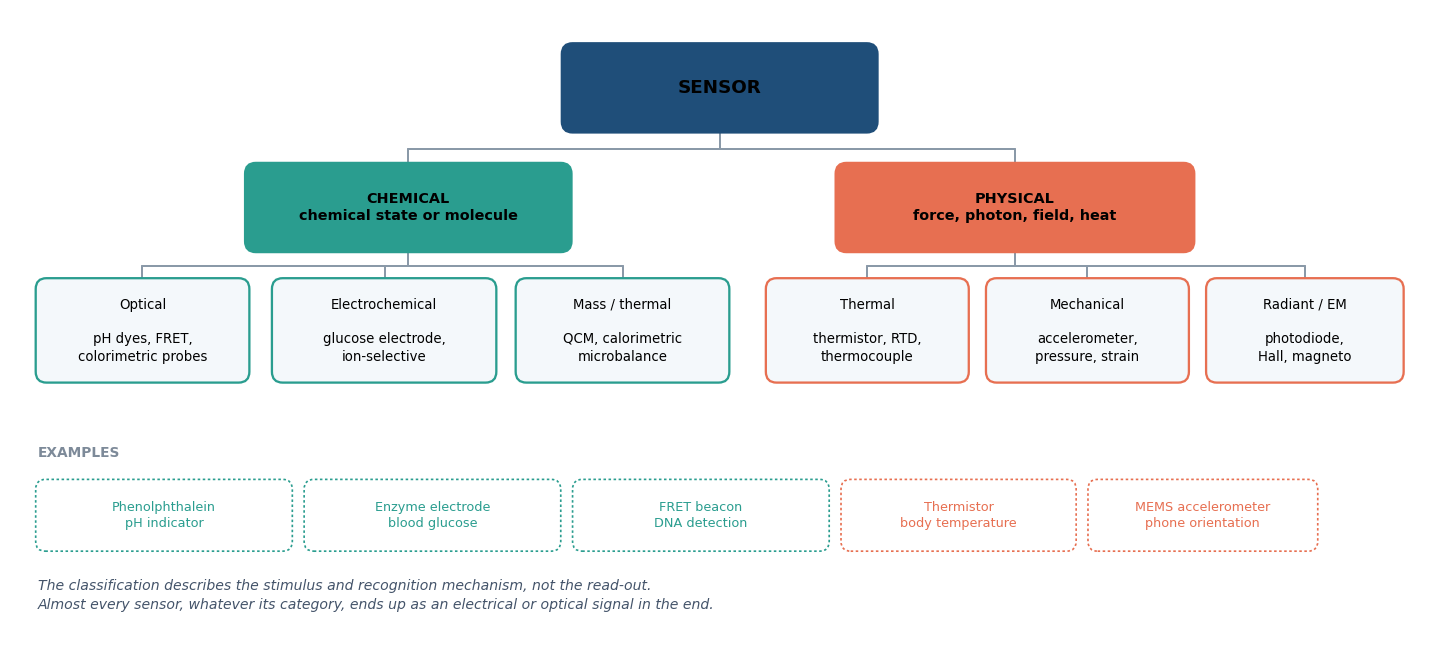

In [4]:
fig, ax = plt.subplots(figsize=(13.2, 6.0))
ax.set_xlim(0, 13.2)
ax.set_ylim(0.30, 6.05)
ax.axis("off")

def node(x, y, w, h, text, face, edge, fontsize=9.4, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.10",
                                linewidth=1.5, edgecolor=edge, facecolor=face, zorder=2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center",
            fontsize=fontsize, fontweight="bold" if bold else "normal", zorder=3,
            linespacing=1.3)

def link(x0, y0, x1, y1, color="#8a99a8"):
    ax.plot([x0, x1], [y0, y1], color=color, lw=1.3, zorder=1, solid_capstyle="round")

# root
node(5.15, 4.95, 2.9, 0.78, "SENSOR", PALETTE["blue"], PALETTE["blue"], fontsize=12, bold=True)
# level 1
node(2.2, 3.85, 3.0, 0.78, "CHEMICAL\nchemical state or molecule", PALETTE["teal"], PALETTE["teal"], bold=True)
node(7.7, 3.85, 3.3, 0.78, "PHYSICAL\nforce, photon, field, heat", PALETTE["coral"], PALETTE["coral"], bold=True)

# root -> bus -> branches
link(6.60, 4.95, 6.60, 4.78)
link(3.70, 4.78, 9.35, 4.78)
link(3.70, 4.78, 3.70, 4.63)
link(9.35, 4.78, 9.35, 4.63)

# level 2 -- chemical
chem = [
    (0.25, 2.65, 1.95, 0.92, "Optical\n\npH dyes, FRET,\ncolorimetric probes", PALETTE["paper"], PALETTE["teal"]),
    (2.45, 2.65, 2.05, 0.92, "Electrochemical\n\nglucose electrode,\nion-selective", PALETTE["paper"], PALETTE["teal"]),
    (4.72, 2.65, 1.95, 0.92, "Mass / thermal\n\nQCM, calorimetric\nmicrobalance", PALETTE["paper"], PALETTE["teal"]),
]
for x, y, w, h, t, f, e in chem:
    node(x, y, w, h, t, f, e, fontsize=8.7)

# level 2 -- physical
phys = [
    (7.05, 2.65, 1.85, 0.92, "Thermal\n\nthermistor, RTD,\nthermocouple", PALETTE["paper"], PALETTE["coral"]),
    (9.10, 2.65, 1.85, 0.92, "Mechanical\n\naccelerometer,\npressure, strain", PALETTE["paper"], PALETTE["coral"]),
    (11.15, 2.65, 1.80, 0.92, "Radiant / EM\n\nphotodiode,\nHall, magneto", PALETTE["paper"], PALETTE["coral"]),
]
for x, y, w, h, t, f, e in phys:
    node(x, y, w, h, t, f, e, fontsize=8.7)

# chemical branches
link(3.70, 3.85, 3.70, 3.70)
link(1.22, 3.70, 5.70, 3.70)
for cx in (1.22, 3.48, 5.70):
    link(cx, 3.70, cx, 3.57)
# physical branches
link(9.35, 3.85, 9.35, 3.70)
link(7.97, 3.70, 12.05, 3.70)
for cx in (7.97, 10.02, 12.05):
    link(cx, 3.70, cx, 3.57)

# bottom examples strip
ax.text(0.25, 1.95, "EXAMPLES", fontsize=9, fontweight="bold", color="#7d8a99")
examples = [
    (0.25, 1.10, 2.35, "Phenolphthalein\npH indicator", PALETTE["teal"]),
    (2.75, 1.10, 2.35, "Enzyme electrode\nblood glucose", PALETTE["teal"]),
    (5.25, 1.10, 2.35, "FRET beacon\nDNA detection", PALETTE["teal"]),
    (7.75, 1.10, 2.15, "Thermistor\nbody temperature", PALETTE["coral"]),
    (10.05, 1.10, 2.10, "MEMS accelerometer\nphone orientation", PALETTE["coral"]),
]
for x, y, w, t, col in examples:
    ax.add_patch(FancyBboxPatch((x, y), w, 0.62, boxstyle="round,pad=0.02,rounding_size=0.09",
                                linewidth=1.1, edgecolor=col, facecolor="#ffffff", ls=(0, (1.5, 1.5)), zorder=2))
    ax.text(x + w / 2, y + 0.31, t, ha="center", va="center", fontsize=8.4,
            color=col, zorder=3, linespacing=1.25)

ax.text(0.25, 0.55,
        "The classification describes the stimulus and recognition mechanism, not the read-out.\n"
        "Almost every sensor, whatever its category, ends up as an electrical or optical signal in the end.",
        fontsize=9.2, color="#44546a", style="italic", linespacing=1.5)

fig.tight_layout()
save_fig(fig, "fig_1_3_sensor_taxonomy")
plt.show()

<p style="text-align:center; font-size:0.92em; color:#555; margin-top:-6px;">
<b>Figure 1.3: A working taxonomy of sensors.</b> Chemical sensors (teal) respond to a chemical state or molecule; physical sensors (orange) respond to forces, photons, fields or heat. The dashed boxes give familiar examples. Real devices often sit on the boundary: a chemiresistor, a glucose biosensor or a plasmonic probe mixes chemical recognition with physical transduction.
</p>

### 2.4 Try it: a chemical sensor you can watch

The widget below is a simplified model of a **pH indicator**. A pH indicator molecule exists in two forms: protonated (acid) and deprotonated (base), with different colours and different absorption spectra. Choose an indicator, move the pH slider, and watch both the molecular state and the optical signal evolve.

This is a **chemical sensor**: the analyte is the proton, the recognition event is protonation/deprotonation, and the transducer is the absorption of light. It is also a lovely example of a sensor with *no electronics at all*: the read-out is your eye (or a spectrophotometer, which is the device).

In [5]:
INDICATORS = {
    "Phenolphthalein": dict(
        pKa=9.4, acid_color=(0.96, 0.96, 0.96), base_color=(0.86, 0.05, 0.45),
        acid_peak=(430, 0.05), base_peak=(552, 1.0), band_width=46,
        transition=(8.2, 10.0), note="colourless → pink/magenta"),
    "Bromothymol blue": dict(
        pKa=7.1, acid_color=(0.93, 0.80, 0.25), base_color=(0.13, 0.35, 0.66),
        acid_peak=(435, 1.0), base_peak=(615, 0.95), band_width=52,
        transition=(6.0, 7.6), note="yellow → blue"),
    "Methyl red": dict(
        pKa=5.1, acid_color=(0.86, 0.16, 0.16), base_color=(0.92, 0.78, 0.18),
        acid_peak=(520, 1.0), base_peak=(430, 0.85), band_width=55,
        transition=(4.4, 6.2), note="red → yellow"),
}

def ph_indicator_demo(pH=7.0, indicator="Bromothymol blue"):
    spec = INDICATORS[indicator]
    pKa = spec["pKa"]
    alpha = 1.0 / (1.0 + 10.0 ** (pKa - pH))          # fraction in base form
    colour = blend(spec["acid_color"], spec["base_color"], alpha)

    wavelengths = np.linspace(380, 750, 500)
    def gauss(centre, height, width=spec["band_width"]):
        return height * np.exp(-0.5 * ((wavelengths - centre) / width) ** 2)

    absorb_acid = gauss(spec["acid_peak"][0], spec["acid_peak"][1])
    absorb_base = gauss(spec["base_peak"][0], spec["base_peak"][1])
    spectrum = (1 - alpha) * absorb_acid + alpha * absorb_base

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.8))

    # ---- left: spectrum + colour swatch --------------------------------
    ax1.plot(wavelengths, spectrum, color=PALETTE["ink"], lw=2.5, zorder=3)
    ax1.fill_between(wavelengths, 0, spectrum, color=colour, alpha=0.55, zorder=2)
    ax1.plot(wavelengths, absorb_acid, color=PALETTE["gold"], lw=1.2, ls="--",
             label="acid (protonated) form", alpha=0.9)
    ax1.plot(wavelengths, absorb_base, color=PALETTE["violet"], lw=1.2, ls="--",
             label="base (deprotonated) form", alpha=0.9)
    ax1.set_xlim(380, 750)
    ax1.set_ylim(0, 1.15)
    ax1.set_xlabel("wavelength (nm)")
    ax1.set_ylabel("absorbance (arbitrary units)")
    ax1.set_title("Optical read-out: the absorption spectrum")
    ax1.legend(loc="upper right", fontsize=8.6)
    style_axes(ax1)

    # swatch: observed solution colour (drawn as a coloured label, avoids overlap)
    lum = 0.2126 * colour[0] + 0.7152 * colour[1] + 0.0722 * colour[2]
    ax1.text(0.025, 0.965, "observed colour", transform=ax1.transAxes,
             ha="left", va="top", fontsize=8.6, fontweight="bold",
             color="white" if lum < 0.55 else "#22333b",
             bbox=dict(boxstyle="round,pad=0.45", facecolor=colour,
                       edgecolor="#3d4a55", linewidth=1.1))

    # ---- right: titration (speciation) curve ---------------------------
    pH_axis = np.linspace(0, 14, 500)
    alpha_axis = 1.0 / (1.0 + 10.0 ** (pKa - pH_axis))
    ax2.plot(pH_axis, alpha_axis, color=PALETTE["blue"], lw=2.8, zorder=2)
    ax2.axvline(pKa, color=PALETTE["gray"], ls=":", lw=1.6,
                label=f"pKa = {pKa:.1f}")
    for edge in spec["transition"]:
        ax2.axvline(edge, color=PALETTE["gray"], ls="--", lw=0.9, alpha=0.45)
    ax2.scatter([pH], [alpha], s=150, color=colour, edgecolor="black", zorder=5,
                linewidth=1.3)
    ax2.annotate(f"pH {pH:.1f}", (pH, alpha), xytext=(10, 14),
                 textcoords="offset points", fontsize=9.2, fontweight="bold")
    ax2.axhspan(0.15, 0.85, color=PALETTE["teal"], alpha=0.07, zorder=1)
    ax2.set_xlim(0, 14)
    ax2.set_ylim(-0.03, 1.05)
    ax2.set_xlabel("pH")
    ax2.set_ylabel("fraction in base form  α")
    ax2.set_title("Chemical state: protonation equilibrium")
    ax2.legend(loc="center right", fontsize=8.8)
    style_axes(ax2)

    state = "mostly deprotonated (base)" if alpha > 0.85 else \
            "mostly protonated (acid)" if alpha < 0.15 else "a mixture of both forms"
    diag = (
        "--- Chemical-sensor diagnostics ---\n"
        f"Indicator: {indicator}   pKa = {pKa:.1f}   transition {spec['transition'][0]:.1f}–{spec['transition'][1]:.1f}   ({spec['note']})\n"
        f"pH = {pH:.1f}   →   fraction base α = {alpha:.3f}   →   {state}\n"
        "Optical signal = mixture of two molecular absorption spectra. The 'colour' is a ratio measurement, so it is\n"
        "robust to lamp intensity — but it reports chemical state, not concentration, and only over a narrow range."
    )
    fig.tight_layout(rect=(0, 0.17, 1, 1))
    diagnostic_box(fig, diag, y=0.012, fontsize=9.0)
    save_fig(fig, "int_2_ph_indicator")
    plt.show()

interact(
    ph_indicator_demo,
    pH=FloatSlider(min=0, max=14, step=0.1, value=7.0, description="pH:",
                   style={"description_width": "initial"},
                   layout=Layout(width="55%"), continuous_update=False),
    indicator=Dropdown(options=list(INDICATORS), value="Bromothymol blue",
                       description="Indicator:",
                       style={"description_width": "initial"},
                       layout=Layout(width="55%")),
);

interactive(children=(FloatSlider(value=7.0, continuous_update=False, description='pH:', layout=Layout(width='…

> **What to notice**
>
> - **The sensor reports a state, not a number.** At pH 7 the indicator is a mixture; the colour encodes the *ratio* of two molecular populations. Calibrating that ratio against pH is what turns a colour into a measurement.
> - **The useful range is narrow.** A pH indicator is informative only within roughly one pH unit of its pKa, the steep, central part of the curve. Outside that range the indicator is saturated at one of its two colours and carries almost no information. Every sensor has this kind of **dynamic range**, and we will formalise it in Section 3.
> - **The chemistry provides selectivity.** The dye responds to protons specifically because protonation is a specific chemical reaction. A dye that reacted with everything would be useless.
> - **The read-out can be a ratio.** Measuring absorbance at two wavelengths (one for each form) cancels out fluctuations in lamp brightness &mdash; an early and elegant example of device-level signal processing.

### 2.5 Try it: FRET: sensing with a molecular ruler

A **FRET pair** is two different fluorescent molecules chosen so that the light emitted by one, the **donor**, overlaps the light absorbed by the other, the **acceptor**. The donor is excited by an external light source. Instead of emitting a photon itself, it can hand its energy to the acceptor through a non-radiative, dipole&ndash;dipole interaction; the acceptor then emits the photon, at a longer wavelength. Whether the handover succeeds depends very strongly on how far apart the two molecules are.

In a FRET sensor the two molecules are not simply floating near each other: they are attached to the same molecular scaffold (a DNA hairpin, a protein, a pair of antibodies), so that a binding event or a conformational change moves them closer together or further apart. The pair is what makes the sensor work. The donor alone would just glow; the acceptor alone would not be excited. Together they convert a nanometre-scale distance into a change in colour and intensity. Common pairs include Cy3/Cy5, FITC/TRITC and GFP/YFP, chosen for spectral overlap, a suitable F&ouml;rster radius, photostability and chemical compatibility.

The transfer efficiency is

$$ E = \frac{1}{1 + (r/R_0)^6} $$

where $r$ is the donor&ndash;acceptor distance and $R_0$ is the F&ouml;rster radius, typically 2&ndash;8&nbsp;nm for common dye pairs. That sixth power makes FRET exquisitely sensitive to distance: doubling $r$ from $R_0$ to $2R_0$ drops the efficiency from 50% to about 1.5%.

Move the distance slider and watch the donor and acceptor emission bands exchange intensity. This is exactly how many **molecular beacons, protease sensors and DNA assays** work: binding or cleavage changes the distance, and the colour of the emitted light reports it.

In [6]:
def fret_ruler_demo(distance=6.0, R0=6.0):
    '''FRET efficiency vs donor-acceptor separation, with emission spectra.'''
    E = 1.0 / (1.0 + (distance / R0) ** 6)

    wavelengths = np.linspace(470, 720, 500)
    donor_spec = np.exp(-0.5 * ((wavelengths - 520) / 28) ** 2)
    acceptor_spec = np.exp(-0.5 * ((wavelengths - 625) / 34) ** 2)
    donor_emit = (1.0 - E) * donor_spec
    acceptor_emit = E * acceptor_spec
    total = donor_emit + acceptor_emit

    # perceived colour: sum of donor (green) and acceptor (red) contributions
    donor_rgb = wavelength_to_rgb(520)
    acceptor_rgb = wavelength_to_rgb(625)
    colour = blend(donor_rgb, acceptor_rgb, E)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.8))

    # ---- left: efficiency curve ---------------------------------------
    r_axis = np.linspace(0.5, 15, 600)
    E_axis = 1.0 / (1.0 + (r_axis / R0) ** 6)
    ax1.plot(r_axis, E_axis, color=PALETTE["blue"], lw=2.8, zorder=2)
    ax1.axvline(R0, color=PALETTE["gray"], ls=":", lw=1.5, label=f"R0 = {R0:.1f} nm  (E = 50%)")
    ax1.axvspan(0.5 * R0, 1.5 * R0, color=PALETTE["teal"], alpha=0.08, zorder=1,
                label="useful measuring range")
    ax1.scatter([distance], [E], s=150, color=colour, edgecolor="black", zorder=5, linewidth=1.3)
    ax1.annotate(f"r = {distance:.1f} nm", (distance, E), xytext=(12, 12),
                 textcoords="offset points", fontsize=9.4, fontweight="bold")
    ax1.set_xlim(0.5, 15)
    ax1.set_ylim(-0.03, 1.05)
    ax1.set_xlabel("donor–acceptor distance r (nm)")
    ax1.set_ylabel("FRET efficiency E")
    ax1.set_title("Distance response: a molecular ruler")
    ax1.legend(loc="upper right", fontsize=8.6)
    style_axes(ax1)

    # ---- right: emission spectra --------------------------------------
    ax2.fill_between(wavelengths, donor_emit, color=donor_rgb, alpha=0.55,
                     label="donor emission (green)")
    ax2.fill_between(wavelengths, acceptor_emit, color=acceptor_rgb, alpha=0.55,
                     label="acceptor emission (red)")
    ax2.plot(wavelengths, total, color=PALETTE["ink"], lw=2.2, label="total emission")
    ax2.set_xlim(470, 720)
    ax2.set_ylim(0, 1.12)
    ax2.set_xlabel("wavelength (nm)")
    ax2.set_ylabel("emission intensity (a.u.)")
    ax2.set_title("Optical read-out: the colour changes")
    ax2.legend(loc="upper right", fontsize=8.4)
    style_axes(ax2)
    lum = 0.2126 * colour[0] + 0.7152 * colour[1] + 0.0722 * colour[2]
    ax2.text(0.025, 0.965, "observed colour", transform=ax2.transAxes,
             ha="left", va="top", fontsize=8.6, fontweight="bold",
             color="white" if lum < 0.55 else "#22333b",
             bbox=dict(boxstyle="round,pad=0.45", facecolor=colour,
                       edgecolor="#3d4a55", linewidth=1.1))

    diag = (
        "--- FRET molecular-ruler diagnostics ---\n"
        f"Distance r = {distance:.1f} nm      Forster radius R0 = {R0:.1f} nm      r/R0 = {distance/R0:.2f}\n"
        f"FRET efficiency E = {100*E:.1f}%   ->   donor emits {100*(1-E):.1f}% of the light, acceptor {100*E:.1f}%\n"
        "The sixth-power dependence makes FRET useful only near r ≈ R0; far away the signal saturates. This is why FRET\n"
        "sensors are engineered so that the binding event moves the pair through the steep part of the curve."
    )
    fig.tight_layout(rect=(0, 0.17, 1, 1))
    diagnostic_box(fig, diag, y=0.012, fontsize=9.0)
    save_fig(fig, "int_3_fret_ruler")
    plt.show()

interact(
    fret_ruler_demo,
    distance=FloatSlider(min=1.0, max=15.0, step=0.1, value=6.0,
                         description="Separation r (nm):",
                         style={"description_width": "initial"},
                         layout=Layout(width="55%"), continuous_update=False),
    R0=FloatSlider(min=3.0, max=9.0, step=0.1, value=6.0,
                   description="Förster radius R₀ (nm):",
                   style={"description_width": "initial"},
                   layout=Layout(width="55%"), continuous_update=False),
);

interactive(children=(FloatSlider(value=6.0, continuous_update=False, description='Separation r (nm):', layout…

> **What to notice**
>
> - **The response is steepest around $r = R_0$.** That is where a small change in distance produces the largest change in signal, and where a sensor designer will deliberately place the operating point.
> - **The sixth power is a design parameter.** By choosing dye pairs with different $R_0$, you can build FRET sensors for distances from about 2 to 8&nbsp;nm. This is not a coincidence: it is the size range of proteins and of the conformational changes they undergo.
> - **The signal is a ratio, not an absolute intensity.** The *change* in colour is what matters, which makes FRET relatively robust against variations in excitation power and probe concentration.
> - **This is already a nanosensor.** The sensing volume is a few cubic nanometres; the transducer is a quantum-mechanical energy transfer; the read-out is light. Section 6 will generalise this pattern.

### 2.6 Chemical vs. physical: a summary

| | **Chemical sensors** | **Physical sensors** |
|---|---|---|
| **Stimulus** | Molecules, ions, chemical state | Force, pressure, light, heat, fields |
| **Recognition** | Chemical reaction, binding, conformation change | Physical law (expansion, piezoelectricity, photoconductivity) |
| **Selectivity comes from** | Chemistry of the recognition element | The physical property being measured |
| **Examples** | pH dyes, enzyme electrodes, FRET probes, chemiresistors, molecularly imprinted polymers | Thermistors, photodiodes, accelerometers, strain gauges, Hall sensors |
| **Typical failure** | Cross-reactivity, fouling, drift, limited lifetime | Environmental interference, nonlinearity, thermal drift |
| **Where nanosensors fit** | Very often here: nanoscale recognition elements and single-molecule detection | Also here: nanomechanical and nanophotonic transducers |

>
> **A useful rule.** If you need to detect *which molecule* is present, you will almost always need chemistry somewhere in the chain. If you need to measure *how much* of a physical quantity is present, a physical transducer is usually simpler and more robust. Nanosensors blur this rule by making the chemical recognition element itself nanoscale, a single binding site, a single pore, a single nanoparticle, which is exactly why they can be so sensitive and so selective at the same time.



## 3. The metrics of performance: knowing your sensor

When designing or choosing a sensor, we must understand its limits and behaviours. Two sensors can cost the same, look the same and output the same kind of voltage, and still be radically different instruments. The difference is captured by a small set of **performance metrics**.

Think of them as the answers to six questions:

1. **How much output do I get per unit of input?** &rarr; sensitivity
2. **How little analyte can I reliably see?** &rarr; limit of detection
3. **Over what range does the sensor behave predictably?** &rarr; dynamic range
4. **Can it tell my analyte apart from its neighbours?** &rarr; selectivity
5. **How close is the reading to the truth?** &rarr; accuracy
6. **How repeatable is the reading?** &rarr; precision

No sensor is good at all six at once. Design is always a negotiation between them, and the rest of this section is about how that negotiation works.

### 3.1 Sensitivity and the calibration curve

**Sensitivity** describes how much the sensor's output signal changes in response to a change in the input stimulus. If the response is approximately linear over the working range, we write

$$ Y = m\,X + b \qquad\text{and}\qquad S = \frac{dY}{dX} \approx m $$

where $Y$ is the output signal, $X$ is the analyte concentration (or stimulus), $m$ is the slope, the sensitivity, and $b$ is the intercept. The plot of $Y$ against $X$ is the **calibration curve**, and it is the single most important piece of documentation a sensor can have.

Sensitivity always has units, and the units matter. A glucose sensor might have a sensitivity of 1.2&nbsp;mV per mg/dL; a thermistor, &minus;4% per &deg;C; a plasmonic sensor, 80&nbsp;nm per refractive-index unit. A high sensitivity means a large signal change for a small stimulus change, but **high sensitivity is not the same as good performance**. You can amplify any signal, including its noise, with a &euro;0.10 operational amplifier. What matters is the **signal-to-noise ratio**, and that is where the next metric comes in.

> **A trap worth naming.** Marketing materials often quote a spectacular sensitivity (or a spectacular "gain") as if it were a figure of merit. It is not. Sensitivity tells you the slope of the calibration curve; it tells you nothing about the noise floor, the selectivity, or whether the sensor drifts. A steep slope through a noisy, drifting baseline can be worse than a shallow slope that is rock-steady.

### 3.2 Limit of detection and dynamic range

The **limit of detection (LoD)** is the lowest concentration or amount of an analyte that a sensor can reliably distinguish from the background noise. If the concentration drops below this threshold, the sensor simply cannot "see" it any more and the signal is buried in the noise.

The standard way to define it is through the **blank**. Measure a sample containing none of the analyte many times. The readings will not all be zero; they will scatter around a mean with a standard deviation $\sigma_{\text{blank}}$. By convention, the smallest *signal* we are willing to call "real" is three standard deviations above the blank:

$$ S_{\text{LoD}} = 3\,\sigma_{\text{blank}} \qquad\Longrightarrow\qquad \text{LoD} = \frac{3\,\sigma_{\text{blank}}}{m} $$

The factor of 3 is a convention, not a law of nature: it corresponds to roughly a 0.1% chance of a false positive if the noise is Gaussian. Some fields use $3.3\sigma$ for the *limit of detection* and reserve the "3 $\sigma$" rule for the *limit of blank*. For our purposes, the important idea is that **the LoD is set by noise divided by sensitivity**, you can lower it by making the transducer quieter or the slope steeper ($m$ is the slope of the calibration curve).

Two related numbers are worth knowing:

- The **limit of quantification (LoQ)** is the concentration at which a measurement becomes quantitatively useful, usually taken as $10\sigma_{\text{blank}}/m$. Below the LoQ you may be able to say "there is something there", but not "how much".
- The **dynamic range** is the span from the LoD to the upper limit of the sensor, the concentration at which the response **saturates**, stops changing, or leaves its linear region. A sensor that is linear from 1&nbsp;nM to 10&nbsp;&micro;M has four decades of dynamic range; a sensor that is linear over a factor of three does not.

Every sensor therefore has three regimes, and confusing them is one of the most common experimental mistakes:

| Regime | Behaviour | What you can say |
|---|---|---|
| **Below LoD** | signal &lt; 3&sigma; | "I cannot detect the analyte" (not "it is absent"!) |
| **Linear / working range** | signal &prop; concentration | "The concentration is X, with uncertainty Y" |
| **Above saturation** | signal flat or nonlinear | "The concentration is above Z" (only a lower bound) |

*The widget below lets you move between these regimes.*

In [ ]:
def calibration_curve_demo(sensitivity=1.2, noise_sigma=1.0, saturation=35.0):
    '''Sensitivity, limit of detection, linear range and saturation, on one plot.'''
    rng = np.random.default_rng(11)

    c = np.linspace(0, 50, 900)
    lod = 3.0 * noise_sigma / sensitivity
    loq = 10.0 * noise_sigma / sensitivity
    sat_conc = saturation / sensitivity

    ideal = np.minimum(sensitivity * c, saturation)
    band_lo = np.clip(ideal - noise_sigma, 0, saturation)
    band_hi = np.clip(ideal + noise_sigma, 0, saturation)

    # measured calibration standards: 5 blanks + 9 standards across the range
    c_std = np.concatenate([np.zeros(5), np.linspace(0.15 * sat_conc, 1.1 * sat_conc, 9)])
    s_std = np.clip(sensitivity * c_std + rng.normal(0, noise_sigma, c_std.size),
                    0, saturation)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 5.15))

    # ---------------------------------------------------------------- left
    ax1.axvspan(0, min(lod, 50), color=PALETTE["red"], alpha=0.055, zorder=0)
    ax1.axvspan(min(lod, 50), min(sat_conc, 50), color=PALETTE["green"], alpha=0.07, zorder=0)
    if sat_conc < 50:
        ax1.axvspan(sat_conc, 50, color=PALETTE["violet"], alpha=0.07, zorder=0)

    ax1.fill_between(c, band_lo, band_hi, color=PALETTE["gray"], alpha=0.22,
                     label="±1σ noise band", zorder=1)
    ax1.plot(c, ideal, color=PALETTE["blue"], lw=2.8, label="ideal response", zorder=3)
    ax1.scatter(c_std, s_std, s=34, color=PALETTE["ink"], edgecolor="white",
                linewidth=0.7, zorder=4, label="calibration standards (measured)")

    if lod < 50:
        ax1.axvline(lod, color=PALETTE["red"], ls="--", lw=1.7,
                    label=f"LoD = 3σ/m = {lod:.1f} mM")
    ax1.axhline(saturation, color=PALETTE["violet"], ls="--", lw=1.5,
                label=f"saturation = {saturation:.0f} mV")
    if sat_conc < 50:
        ax1.axvline(sat_conc, color=PALETTE["violet"], ls=":", lw=1.7)

    ax1.set_xlim(0, 50)
    ax1.set_ylim(-2, saturation + 8)
    ax1.set_xlabel("analyte concentration (mM)")
    ax1.set_ylabel("sensor output (mV)")
    ax1.set_title("Signal response: three regimes")
    ax1.legend(loc="upper left", fontsize=7.4, frameon=True,
               framealpha=0.92, edgecolor="#cfd8e0")
    style_axes(ax1)

    # zone labels, placed in free space rather than under the legend
    ax1.text(lod * 0.55, saturation * 0.55, "noise floor", rotation=90,
             ha="center", va="center", fontsize=7.8, color=PALETTE["red"], alpha=0.9)
    mid = (min(lod, 50) + min(sat_conc, 50)) / 2
    ax1.text(mid, 2.0, "linear working range",
             ha="center", va="bottom", fontsize=8.0, color=PALETTE["green"],
             fontweight="bold")
    if sat_conc < 50:
        ax1.text((sat_conc + 50) / 2, saturation * 0.55, "saturated\n(above range)",
                 ha="center", va="center", fontsize=8.0, color=PALETTE["violet"])

    # ---------------------------------------------------------------- right
    cm = np.logspace(-2, np.log10(50), 500)
    snr = sensitivity * cm / noise_sigma
    ax2.loglog(cm, snr, color=PALETTE["blue"], lw=2.6, zorder=2)
    ax2.axhline(3, color=PALETTE["red"], ls="--", lw=1.5, label="SNR = 3  (detection)")
    ax2.axhline(10, color=PALETTE["gold"], ls="--", lw=1.5, label="SNR = 10  (quantification)")
    if lod < 50:
        ax2.axvline(lod, color=PALETTE["red"], ls=":", lw=1.6)
        ax2.scatter([lod], [3], s=70, color=PALETTE["red"], zorder=5, edgecolor="white")
    if loq < 50:
        ax2.axvline(loq, color=PALETTE["gold"], ls=":", lw=1.6)
    ax2.set_xlim(1e-2, 50)
    snr_top = max(10.0, 1.6 * sensitivity * 50 / noise_sigma)
    ax2.set_ylim(0.1, snr_top)
    ax2.set_xlabel("analyte concentration (mM)")
    ax2.set_ylabel("signal-to-noise ratio  (S/σ)")
    ax2.set_title("Signal-to-noise view of the same sensor")
    ax2.legend(loc="upper left", fontsize=8.2, frameon=True,
               framealpha=0.92, edgecolor="#cfd8e0")
    style_axes(ax2)
    ax2.text(0.97, 0.06, "LoD = where the line crosses SNR = 3",
             transform=ax2.transAxes, ha="right", va="bottom", fontsize=8.2,
             color=PALETTE["gray"], style="italic")

    # ---------------------------------------------------------------- diagnosis
    if sat_conc <= lod:
        verdict = "NO WORKING RANGE: the noise floor reaches saturation — this sensor cannot quantify anything."
    elif sat_conc / lod < 5:
        verdict = "NARROW range: the linear window is less than a factor of five — usable only for a known sample."
    elif sat_conc / lod < 100:
        verdict = "USEFUL range: the sensor can quantify over roughly one to two decades."
    else:
        verdict = "WIDE range: the sensor quantifies over more than two decades."

    diag = (
        "--- Calibration diagnostics ---\n"
        f"Sensitivity m = {sensitivity:.2f} mV/mM      Noise σ = {noise_sigma:.2f} mV      Saturation = {saturation:.0f} mV\n"
        f"LoD = 3σ/m = {lod:.2f} mM      LoQ = 10σ/m = {loq:.2f} mM      Linear range: {lod:.2f} – {sat_conc:.2f} mM\n"
        f"Dynamic range factor = {sat_conc / lod:.0f}×      Verdict: {verdict}"
    )
    fig.tight_layout(rect=(0, 0.19, 1, 1))
    diagnostic_box(fig, diag, y=0.010, fontsize=8.8)
    save_fig(fig, "int_4_calibration_lod")
    plt.show()

interact(
    calibration_curve_demo,
    sensitivity=FloatSlider(min=0.3, max=3.0, step=0.1, value=1.2,
                            description="Sensitivity (mV/mM):",
                            style={"description_width": "initial"},
                            layout=Layout(width="56%"), continuous_update=False),
    noise_sigma=FloatSlider(min=0.2, max=3.0, step=0.1, value=1.0,
                            description="Noise σ (mV):",
                            style={"description_width": "initial"},
                            layout=Layout(width="56%"), continuous_update=False),
    saturation=FloatSlider(min=15.0, max=45.0, step=1.0, value=35.0,
                           description="Saturation level (mV):",
                           style={"description_width": "initial"},
                           layout=Layout(width="56%"), continuous_update=False),
);

interactive(children=(FloatSlider(value=1.2, continuous_update=False, description='Sensitivity (mV/mM):', layo…

> **What to notice**
>
> - **The LoD and the saturation point are not properties of the "sensor material" alone.** They are properties of the whole measurement: lower the noise (better shielding, averaging, cooling) and the LoD moves left; raise the saturation ceiling and the working range extends right.
> - **A sensor can have a fantastic LoD and a useless range.** Look at what happens when you push the noise up: the LoD moves right, the working range shrinks, and at some point the sensor becomes a yes/no detector.
> - **The SNR plot is just the calibration curve in disguise.** On a log&ndash;log plot, the linear response becomes a straight line and the detection limit is simply where it crosses SNR&nbsp;=&nbsp;3. This is the most common way to *report* a LoD in the literature.
> - **Below the LoD, "not detected" does not mean "not present".** It means "below my ability to distinguish from noise". This distinction has real consequences in medicine, food safety and environmental regulation.

### 3.3 Selectivity, and the almond that smells like cyanide

Sensitivity and LoD answer "how much?", but only if the sensor is responding to the thing you think it is. **Selectivity** is the ability to measure the target analyte exactly, even in a crowded, messy environment. A sensor that responds beautifully to glucose *and* to vitamin C is not a glucose sensor; it is a sugar-and-vitamin sensor with a labelling problem.

The consequences are easiest to appreciate with a biological example. **Almonds versus cyanide.** To the human nose, benzaldehyde, the organic compound responsible for the smell of almonds, and hydrogen cyanide (HCN) smell almost identical. Our olfactory system has an excellent *limit of detection* for this scent profile: it can trigger a response at remarkably low concentrations. But our biological receptors cannot reliably differentiate the non-toxic almond molecule from the deadly gas. The sensor is sensitive; it is simply **not selective**. Even a tiny amount of the wrong molecule produces a confident, and potentially fatal, sensation of "almonds".

This is the essential failure mode of a non-selective sensor: **it does not report an error, it reports a wrong answer with the same confidence as a right one.** Sensitivity without selectivity is dangerous precisely because it looks like success.

In real instruments, selectivity is engineered in several ways: a chemically selective receptor (an antibody, a molecularly imprinted polymer, an enzyme), a size-selective nanostructure (a nanopore that only admits molecules of a certain size), a spectroscopic fingerprint (Raman bands that identify a molecule by its vibrations), or a sensor array whose combined pattern is decoded chemometrically (the "electronic nose"). No single strategy is perfect; the practical question is always "selective enough for *this* sample matrix?"

The widget below reduces all of this to a single number, **k**, the **cross-talk coefficient**. It answers a simple question: if the interferent is present at some concentration, how much of a target signal does the sensor pretend to see? A value of k = 0 means the interferent is invisible. A value of k = 0.05 means that a sample containing only the interferent is read as if 5% of that concentration were the target. A value of k = 1 means the sensor cannot tell the two apart at all. In the widget, k is the slider labelled **cross-talk coefficient**, and the target and interferent concentrations are the other two sliders.

> **Try it.** Watch how a small amount of cross-talk becomes a large relative error when the target concentration is low, the regime where real samples usually live.

In [8]:
def selectivity_demo(target=10.0, interferent=50.0, cross_talk=0.05):
    '''One target, one interferent: how cross-talk becomes an error.'''
    interference_signal = cross_talk * interferent
    reported = target + interference_signal
    abs_error = reported - target
    rel_error = 100.0 * abs_error / target

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.9))

    # ---------------------------------------------------------------- left: what is reported
    ax1.bar([0], [target], width=0.5, color=PALETTE["blue"], edgecolor="white")
    ax1.bar([0], [interference_signal], width=0.5, bottom=[target],
            color=PALETTE["coral"], edgecolor="white")
    ax1.axhline(target, color=PALETTE["gold"], lw=2.2, ls="--")
    ax1.text(-0.76, target + 0.5, "true target", color=PALETTE["gold"],
             fontsize=8.6, fontweight="bold", ha="left", va="bottom")
    ax1.text(0, target * 0.5, f"target\n{target:.1f}",
             ha="center", va="center", color="white", fontsize=9.2,
             fontweight="bold")
    if interference_signal > 0.6:
        ax1.text(0, target + interference_signal / 2, f"+{interference_signal:.1f}",
                 ha="center", va="center", color="white", fontsize=8.0,
                 fontweight="bold")
    else:
        ax1.annotate(f"+{interference_signal:.1f}",
                     xy=(0.26, target + max(interference_signal / 2, 0.4)),
                     xytext=(0.36, target + 2.0), fontsize=8.2,
                     color=PALETTE["coral"],
                     arrowprops=dict(arrowstyle="-", color=PALETTE["coral"], lw=1.0))
    ax1.text(0, reported + 1.2, f"reported\n{reported:.1f}",
             ha="center", va="bottom", fontsize=9.4, fontweight="bold",
             color=PALETTE["coral"] if cross_talk > 0.02 else PALETTE["blue"])
    ax1.annotate("", xy=(0.33, reported), xytext=(0.33, target),
                 arrowprops=dict(arrowstyle="<->", color=PALETTE["coral"], lw=1.5))
    ax1.text(0.37, (target + reported) / 2, f"error\n{abs_error:+.1f}",
             fontsize=8.6, color=PALETTE["coral"], va="center")
    ax1.set_xlim(-0.8, 0.85)
    ax1.set_ylim(0, max(reported * 1.65, target * 1.9, 5))
    ax1.set_xticks([0], ["sample"])
    ax1.set_ylabel("reported concentration (a.u.)")
    ax1.set_title("What the device reports")
    style_axes(ax1)

    # ---------------------------------------------------------------- right: error vs interferent
    interf_axis = np.linspace(0, 200, 400)
    rel_axis = 100.0 * cross_talk * interf_axis / target
    ax2.plot(interf_axis, rel_axis, color=PALETTE["blue"], lw=2.6, zorder=2)
    ax2.axhspan(-10, 10, color=PALETTE["green"], alpha=0.08, zorder=0)
    ax2.axhline(0, color=PALETTE["gray"], lw=0.8)
    ax2.axhline(10, color=PALETTE["green"], ls="--", lw=1.2, alpha=0.7)
    ax2.axhline(-10, color=PALETTE["green"], ls="--", lw=1.2, alpha=0.7)
    ax2.scatter([interferent], [rel_error], s=130,
                color=PALETTE["coral"] if abs(rel_error) > 10 else PALETTE["green"],
                edgecolor="black", zorder=5, linewidth=1.2)
    ax2.annotate(f"{rel_error:+.0f}%", (interferent, rel_error), xytext=(10, 10),
                 textcoords="offset points", fontsize=9.4, fontweight="bold")
    ax2.set_xlim(0, 200)
    ax2.set_ylim(-5, max(60, rel_error * 1.35))
    ax2.set_xlabel("interferent concentration (a.u.)")
    ax2.set_ylabel("relative error in reported target (%)")
    ax2.set_title("Error grows with the interferent")
    style_axes(ax2)
    ax2.text(0.97, 0.06, "green band = ±10% error tolerance",
             transform=ax2.transAxes, ha="right", va="bottom", fontsize=8.2,
             color=PALETTE["gray"], style="italic")

    if abs(rel_error) < 5:
        verdict = "EXCELLENT selectivity for this sample: the interferent is invisible."
    elif abs(rel_error) < 15:
        verdict = "GOOD: the cross-talk is within a typical assay error budget."
    elif abs(rel_error) < 30:
        verdict = "MARGINAL: the interferent is eating the error budget."
    elif abs(rel_error) < 50:
        verdict = "POOR: the reported value is strongly distorted by cross-talk."
    else:
        verdict = "UNUSABLE: the sensor is mostly measuring the interferent, not the target."

    diag = (
        "--- Selectivity diagnostics ---\n"
        f"True target = {target:.1f}      Interferent = {interferent:.1f}      Cross-talk coefficient k = {cross_talk:.3f}\n"
        f"Interferent contributes {interference_signal:.2f}  →  reported {reported:.2f}  →  error {abs_error:+.2f} ({rel_error:+.0f}%)\n"
        f"Verdict: {verdict}"
    )
    fig.tight_layout(rect=(0, 0.19, 1, 1))
    diagnostic_box(fig, diag, y=0.010, fontsize=8.9)
    save_fig(fig, "int_5_selectivity")
    plt.show()

interact(
    selectivity_demo,
    target=FloatSlider(min=1.0, max=100.0, step=1.0, value=10.0,
                       description="True target:",
                       style={"description_width": "initial"},
                       layout=Layout(width="56%"), continuous_update=False),
    interferent=FloatSlider(min=0.0, max=200.0, step=5.0, value=50.0,
                            description="Interferent level:",
                            style={"description_width": "initial"},
                            layout=Layout(width="56%"), continuous_update=False),
    cross_talk=FloatSlider(min=0.0, max=0.5, step=0.01, value=0.05,
                           description="Cross-talk coefficient k:",
                           style={"description_width": "initial"},
                           layout=Layout(width="56%"), continuous_update=False),
);

interactive(children=(FloatSlider(value=10.0, continuous_update=False, description='True target:', layout=Layo…

> **What to notice**
>
> - **The error is a ratio, not an amount.** A fixed amount of cross-talk is harmless when the target is abundant and catastrophic when the target is trace. This is why selectivity is hardest at low concentrations, exactly where the interesting biology and the strictest regulations live.
> - **A selective sensor can be made from a non-selective transducer.** The biochemistry does the recognition; the transducer only has to report that *something* bound. This separation of concerns is the central design idea of modern biosensing, and it is why the recognition element, not the electronics, is often the hardest part of a nanosensor.

### 3.4 Accuracy vs. precision

These two terms are often confused in everyday speech, but in sensor science they mean entirely different things:

- **Accuracy** is how close a measurement is to the true, accepted value. It is about *bias*.
- **Precision** is how reproducible or repeatable the measurements are when taken under the same conditions. It is about *scatter*.

The classic analogy is a dartboard. If all your darts hit the bullseye, you are accurate *and* precise. If your darts are tightly clustered together but far from the bullseye, you are **precise but inaccurate**, usually a systematic calibration error. If your darts are scattered all over the board but their average centre is the bullseye, you are **accurate but imprecise**, the average is right, but any single measurement may be far off. And if the darts are both scattered and off-centre, you have neither.

The distinction matters because the two failures have different remedies:

| | **Accurate** | **Inaccurate (biased)** |
|---|---|---|
| **Precise** | Trustworthy. Do not touch it. | **Recalibrate.** The random error is small; a systematic offset is the problem. |
| **Imprecise** | **Average, improve SNR.** The mean is fine but single readings are unreliable. | **Fix both.** Anything you do to one error leaves the other. |

Mathematically, if a measurement has bias $b$ and standard deviation $\sigma$, the total **root-mean-square error** is

$$ \text{RMSE} = \sqrt{b^2 + \sigma^2} $$

which makes the two contributions explicit: a sensor with a small bias but large noise and a sensor with small noise but large bias can have the same RMSE, yet require completely different fixes. Calibration removes bias; averaging reduces $\sigma$ (by $\sqrt{N}$ for $N$ independent measurements) but does nothing to bias.

> **Try it.** The widget below turns the dartboard analogy into a measurement simulation. **Accuracy** controls the systematic offset of the readings (the distance of the cluster from the bullseye); **precision** controls the random scatter. Watch the two panels: the left one is the abstract dartboard, the right one is the same data as a sequence of repeated assays, which is how you would actually see it in the laboratory.

In [ ]:
def accuracy_precision_demo(accuracy=0.9, precision=0.9):
    '''Bias vs scatter: the dartboard and the bench.'''
    rng = np.random.default_rng(42)
    n = 20
    true_value = 100.0

    bias = (1.0 - accuracy) * 30.0          # systematic offset, 0...30
    sigma = 2.0 + (1.0 - precision) * 25.0  # random scatter, 2...27

    x = rng.normal(0.0, sigma, n)
    y = bias + rng.normal(0.0, sigma, n)
    readings = true_value + bias + rng.normal(0.0, sigma, n)

    rmse = np.sqrt(bias ** 2 + sigma ** 2)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.0),
                                gridspec_kw={"width_ratios": [0.88, 1.12]})

    # ---------------------------------------------------------------- left: dartboard
    for r, col in zip([45, 36, 27, 18, 9],
                      ["#f2f5f8", "#e4ebf1", "#d4dfe8", "#c3d2df", "#b1c4d4"]):
        ax1.add_patch(Circle((0, 0), r, color=col, zorder=1))
    for th in [0]:
        ax1.axhline(0, color="white", lw=1.2, zorder=2)
        ax1.axvline(0, color="white", lw=1.2, zorder=2)
    ax1.scatter(x, y, s=62, color=PALETTE["coral"], edgecolor="black",
                linewidth=0.7, zorder=4, label="individual readings")
    ax1.scatter([x.mean()], [y.mean()], marker="X", s=160, color=PALETTE["violet"],
                edgecolor="black", linewidth=0.8, zorder=6, label="centre of the cluster")
    ax1.scatter([0], [0], marker="*", s=340, color=PALETTE["gold"],
                edgecolor="black", linewidth=0.9, zorder=7, label="true value")
    ax1.set_xlim(-52, 52)
    ax1.set_ylim(-52, 52)
    ax1.set_aspect("equal")
    ax1.set_title("The dartboard: bias vs. scatter")
    ax1.legend(loc="lower left", fontsize=8.0, frameon=True,
               framealpha=0.92, edgecolor="#cfd8e0", bbox_to_anchor=(0.0, 0.0))
    ax1.axis("off")

    # ---------------------------------------------------------------- right: repeated assays
    runs = np.arange(1, n + 1)
    mean_reading = readings.mean()
    ax2.axhline(true_value, color=PALETTE["gold"], lw=2.4, ls="-",
                label=f"true value = {true_value:.0f}")
    ax2.axhline(mean_reading, color=PALETTE["violet"], lw=1.8, ls=":",
                label=f"mean of readings = {mean_reading:.1f}")
    ax2.fill_between([0.5, n + 0.5], mean_reading - sigma, mean_reading + sigma,
                     color=PALETTE["coral"], alpha=0.10, zorder=1,
                     label="±1σ of the readings")
    ax2.plot(runs, readings, color=PALETTE["blue"], lw=1.4, marker="o", ms=6,
             mfc=PALETTE["coral"], mec="black", mew=0.6, zorder=3)
    ax2.set_xlim(0.5, n + 0.5)
    ax2.set_xticks(np.arange(2, n + 1, 2))
    ax2.set_xlabel("sequential measurement run #")
    ax2.set_ylabel("reported value (units of the measurand)")
    ax2.set_title("The bench: the same data as repeated assays")
    ax2.legend(loc="upper right", fontsize=8.2, frameon=True,
               framealpha=0.92, edgecolor="#cfd8e0")
    style_axes(ax2)

    # ---------------------------------------------------------------- diagnosis
    if accuracy >= 0.8 and precision >= 0.8:
        verdict = "TRUSTWORTHY: accurate and precise. This is what good metrology looks like."
    elif accuracy < 0.5 and precision >= 0.8:
        verdict = "PRECISE BUT INACCURATE: a calibration or systematic-error problem. Fix the offset, not the noise."
    elif accuracy >= 0.8 and precision < 0.5:
        verdict = "ACCURATE ON AVERAGE, BUT NOISY: average more readings or improve the transducer/electronics."
    else:
        verdict = "NEITHER ACCURATE NOR PRECISE: both a systematic and a random failure. Do not use this measurement."

    diag = (
        "--- Accuracy vs precision ---\n"
        f"Systematic bias = {bias:+.1f} units      Random scatter σ = {sigma:.1f} units      RMSE = {rmse:.1f} units\n"
        f"Accuracy setting = {accuracy:.2f}      Precision setting = {precision:.2f}      True value = {true_value:.0f}\n"
        f"Verdict: {verdict}"
    )
    fig.tight_layout(rect=(0, 0.19, 1, 1))
    diagnostic_box(fig, diag, y=0.010, fontsize=8.9)
    save_fig(fig, "int_6_accuracy_precision")
    plt.show()

interact(
    accuracy_precision_demo,
    accuracy=FloatSlider(min=0.0, max=1.0, step=0.05, value=0.9,
                         description="Accuracy (1 = perfect):",
                         style={"description_width": "initial"},
                         layout=Layout(width="56%"), continuous_update=False),
    precision=FloatSlider(min=0.0, max=1.0, step=0.05, value=0.9,
                          description="Precision (1 = perfect):",
                          style={"description_width": "initial"},
                          layout=Layout(width="56%"), continuous_update=False),
);

interactive(children=(FloatSlider(value=0.9, continuous_update=False, description='Accuracy (1 = perfect):', l…

> **What to notice**
>
> - **A miscalibrated sensor can look beautiful.** Set accuracy low and precision high: the readings are tightly clustered and completely wrong. This is the single most common failure mode in real laboratories, because precision is visible within an experiment while bias is not.
> - **Bias and noise are independent.** Moving the accuracy slider translates the cluster; moving the precision slider inflates it. Neither slider changes the other, which is exactly why you need two numbers to describe a measurement, not one.
> - **RMSE combines both.** Watch how a moderate bias and a moderate scatter can give the same RMSE. If a specification sheet quotes only RMSE, you cannot tell whether the sensor needs calibration or better shielding.
> - **Averaging is not a cure for bias.** With precision low and accuracy high, averaging enough readings will eventually recover the true value. With accuracy low, averaging just gives you a very precise wrong answer.

### 3.5 The full specification sheet

Beyond the six headline metrics, a sensor's datasheet usually includes a number of secondary characteristics. They are not secondary in practice, most sensors that work in the laboratory fail in the field because of one of them.

| Metric | The question it answers | Typical definition / unit | What usually goes wrong |
|---|---|---|---|
| **Sensitivity** | How much output per unit input? | $S = dY/dX$; mV/mM, %/&deg;C, nm/RIU | Confused with "gain"; only valid in the linear range |
| **Limit of detection (LoD)** | How little can be seen? | $3\sigma_{\text{blank}}/m$; M, ppb, copies/mL | Reported from too few blanks; not a true absence limit |
| **Limit of quantification (LoQ)** | How little can be quantified? | $\approx 10\sigma_{\text{blank}}/m$ | Overlooked; LoD values are quoted as if quantitative |
| **Dynamic range** | Over what span is it usable? | From LoD to saturation; decades | Saturation and nonlinearity are not checked |
| **Selectivity** | Can it tell analytes apart? | Relative response to interferent, k; dimensionless | Matrix effects in real samples, not buffer |
| **Accuracy / bias** | How close to the truth? | Bias; same units as measurand | Calibration standards are wrong; drift |
| **Precision / repeatability** | How repeatable is a reading? | $\sigma$, %CV | Noise, temperature, operator, sample handling |
| **Reproducibility** | Do different devices agree? | Inter-device spread | Fabrication variation, a huge issue for nanosensors |
| **Response time** | How fast does it answer? | $t_{90}$, seconds | Slow diffusion or binding kinetics |
| **Drift** | Does it stay calibrated? | %/hour or %/day | Fouling, aging, hydration, temperature |
| **Hysteresis** | Does it remember its history? | Difference between up and down sweeps | Material memory, adsorption |
| **Reversibility** | Can it be reused? | Recovery fraction | Irreversible binding, poisoning |
| **Operating environment** | Where does it survive? | pH, temperature, humidity, pressure | Out-of-spec use in the field |
| **Cost / power / size** | Can it be deployed? | &euro;, mW, mm&sup3; | The reason many excellent sensors never leave the lab |

> **A definition worth memorising.** The **fitness for purpose** of a sensor is not a property of the sensor; it is a relationship between the sensor's metrics and the requirements of a specific application. A sensor with a 5% bias is unacceptable for a clinical glucose assay and perfectly fine for a home compost moisture monitor. **There is no such thing as "the best sensor", only the best sensor *for a job*.**

### 3.6 Three requirement sets, three different sensors

To see how the metrics interact, compare three real sensing problems. In each case, the "best" sensor is the one whose weak metrics fall outside the requirements.

| Requirement | Glucose monitoring (clinical/home) | Air-quality NO2 monitoring | Single-molecule DNA detection |
|---|---|---|---|
| **Target range** | 40&ndash;400 mg/dL | ppb to low ppm | Single molecules, no useful concentration |
| **Key metric** | Accuracy (bias) and speed | LoD and long-term drift | Selectivity at the single-molecule level |
| **Tolerated error** | &plusmn;15% (whole measurement) | &plusmn;10&ndash;20% plus drift budget | Any error is a wrong base call |
| **Environment** | Blood, a disposable strip, 5&nbsp;s | Outdoors, months, humidity, temperature | Controlled electrolyte, pA currents |
| **Why it is hard** | Interferents and manufacturing spread | Fouling and calibration drift | Noise at the picoampere level |
| **Typical transducer** | Electrochemical (enzyme electrode) | Chemiresistive or optical | Nanopore ionic current |

Notice how different the priorities are. The glucose sensor is judged mainly on **bias and speed**; the air-quality sensor on **LoD and drift**; the DNA sensor on **selectivity and single-molecule signal-to-noise**. Chapter 1 is about learning to see a sensor through this matrix, rather than through a single headline number.

> **Pause and think.** Pick the sensor in your phone that you trust most and the one you trust least. Which of the metrics above explains the difference? (Hint: it is probably not sensitivity.)



## 4. Why do we need sensors?

Sensors are like the sensory organs of human civilisation. They fundamentally expand our capabilities in three ways: they extend where we can go, they let us see systems that are too large or too slow to perceive, and they provide the raw material for prediction and artificial intelligence.

### 4.1 Expanding our knowledge

Sensors allow us to "be" where human biology cannot survive. They sit at the crushing depths of the Mariana Trench, nearly 11&nbsp;km down, where the pressure is over 1,000 times atmospheric. They withstand the freezing vacuum and radiation of space on Martian rovers. They peer inside blazing nuclear reactors and inside living cells. They extend our vision into the infrared and our hearing into the infrasonic, and they detect particles and gravitational waves that our senses could never register.

Every extension of the observable range is an extension of the questions science can ask. The thermometer made thermodynamics quantitative; the photodetector made modern astronomy possible; the seismometer turned the solid Earth into an object we can listen to. The instrument does not merely measure; it *defines the frontier* of what can be investigated.

### 4.2 Understanding complex systems

Earthquakes, global weather patterns, ocean currents and wildlife migrations are massive, chaotic systems. No single measurement can describe them. But by deploying vast networks of distributed sensors, we can gather synchronised data that reveals the macro-patterns of our world.

The key word is **distributed**. A single weather station tells you about its own garden. Ten thousand weather stations, feeding a numerical model, tell you where a storm will be tomorrow. A single seismometer detects a tremor; a global network of them locates the epicentre and images the interior of the planet. Ocean floats drift with currents and report temperature and salinity from below the surface; satellites measure the colour of the sea, from which chlorophyll and plankton blooms are inferred; GPS tags on migratory birds reveal flyways that were invisible for centuries.

In each case, the sensor network converts *isolated facts* into a *system-level picture*. This is one of the reasons nanosensors matter: the smaller and cheaper a sensor becomes, the more of them you can deploy, and the finer the picture you can reconstruct.

![City map with air-quality sensor icons overlaid on a colour-coded pollution index.](figures/fig_1_4_sensor_network.jpg)

<p style="text-align:center; font-size:0.92em; color:#555;">
<b>Figure 1.4: A distributed air-quality sensor network.</b> Each white icon is a sensor node; combining their readings produces a street-level pollution map, from poor (red) to good (green). No single sensor could produce this picture.
</p>

### 4.3 Powering predictive models and AI

We are living in the age of artificial intelligence. However, an AI model is only as good as the data used to train it. This brings us to a fundamental rule of data science: **GIGO: Garbage In, Garbage Out.**

If your sensors yield noisy, uncalibrated or flawed data, your AI will generate flawed, dangerous predictions. A model trained on miscalibrated thermometers learns the bias. A diagnostic algorithm trained on data from one hospital learns that hospital's population, not the disease. A self-driving car trained on clear-weather camera data fails in rain. Sensor calibration, data cleaning and preprocessing are the unsung heroes of the modern AI revolution.

The reverse is also true, and it is the optimistic version of the same idea: **better sensors unlock better models.** The explosion of machine learning in the life sciences was enabled not only by faster GPUs but by cheap, high-throughput sequencing, imaging and mass spectrometry. When measurement becomes cheaper and more precise, the space of answerable questions expands.

> **The GIGO principle in one sentence.** A prediction system can never be more reliable than the measurements that feed it; every gain in model sophistication makes the quality of the input data *more* important, not less.

The most famous real-world example of GIGO did not happen in a laboratory.

#### Case study: Tay, the chatbot that learned from the internet

On 23 March 2016, Microsoft Research released **Tay**, a Twitter chatbot designed to talk like a 19-year-old American girl and to improve by learning from the conversations it had with users (handle `@TayandYou`). It was also given a "repeat after me" ability: if a user asked it to repeat a phrase, it would.

Within hours, users had found the weakness. They fed Tay racist, sexist and antisemitic statements, and it repeated and amplified them. It denied that the Holocaust had happened, produced offensive jokes and became exactly the kind of account its creators had not intended. It posted more than 96,000 tweets in less than a day. Microsoft deleted the worst posts and took the account offline 16 hours after launch. On 25 March the company apologised, describing the episode as a coordinated attack that had exploited a vulnerability, and it later replaced Tay with a new bot, Zo.

| What went in | What came out | What it teaches |
|---|---|---|
| Unmoderated Twitter conversations, including deliberately offensive prompts | Racist, sexist and antisemitic tweets; Holocaust denial | Data quality is a design requirement, not a preprocessing afterthought |
| A "repeat after me" feature with no guardrails | Users could make the bot say almost anything | A chain with no validation stage will faithfully reproduce its worst input |
| Online learning from user reactions | Rapid amplification of the worst behaviour | Feedback loops can turn a small bias into a large failure |
| No independent test of acceptable output | The failure became visible only in public | You need a validation set that represents what you actually care about |

The connection to sensors is direct. Replace "unmoderated Twitter conversations" with "an uncalibrated sensor", and the rest of the story is familiar. A sensor that is noisy, drifting or wrongly calibrated produces data that look like measurements but are not; a model trained on those data learns the error, and a control system wired to that model acts on it. Tay's users were, in effect, a deliberately corrupted data source, but a noisy sensor needs no adversary at all: it corrupts the data by itself. In both cases the failure is easy to miss because the output is fluent, plausible and confident.

Three lessons follow, and they apply to any measurement pipeline:

1. **Data quality is a design requirement.** Calibration, blank measurements, reference channels, cleaning and outlier detection are not optional extras at the end of a project; they are part of the sensor.
2. **Feedback loops amplify whatever they are fed.** A model that learns from its own users, or a controller that adjusts a process based on a drifting sensor, will amplify a small bias until it becomes a large failure.
3. **Validate against what you care about.** A model can fit its training data perfectly and still be wrong about the world; a sensor can be stable and still be measuring the wrong thing. Independent validation is the only defence.

> **A note on history.** Tay was a 2016 research experiment, not a modern large language model, and today's systems include filters and safeguards that Tay lacked. The principle has not changed: a system cannot learn its way out of bad data. Better models make better use of good data; they do not turn garbage into truth.

*Sources: [Tay (chatbot), Wikipedia](https://en.wikipedia.org/wiki/Tay_(chatbot)) and [Microsoft's post-mortem, "Learning from Tay's introduction"](https://blogs.microsoft.com/blog/2016/03/25/learning-tays-introduction/).*

### 4.4 A short history of sensing

The ideas in this chapter did not appear all at once. Figure 1.5 places a few milestones on a (deliberately compressed) timeline, from the first practical thermometers to the pocket-sized nanopore sequencer.

Two things are worth noticing in the timeline. First, the **pace is accelerating**: the interval between a scientific principle and a commercial sensor has shrunk from centuries to years. Second, the **nanoscale era** at the right of the figure is not just "smaller versions of old sensors". It is a new regime in which the sensing element itself is comparable in size to the molecules it measures, which is the subject of Section 6.

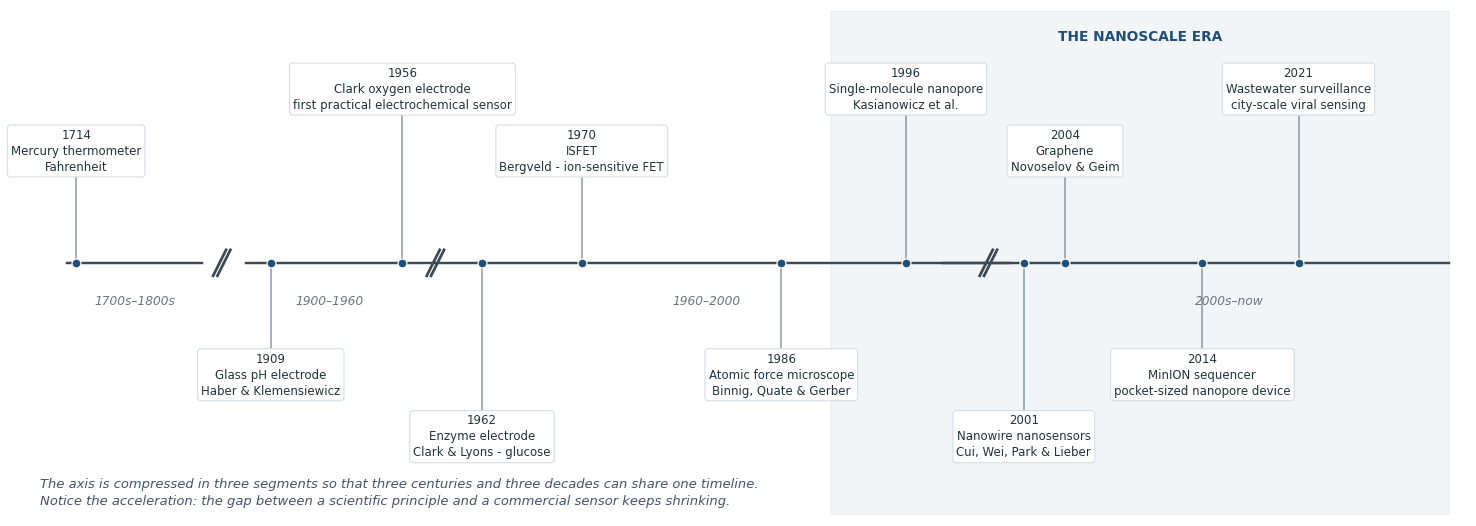

In [10]:
# piecewise-compressed year axis so that 300 years and 30 years both fit
def year_to_x(year):
    if year < 1900:
        return 0.0 + (year - 1700) / 200.0 * 1.25
    if year < 1960:
        return 1.65 + (year - 1900) / 60.0 * 1.55
    if year < 2000:
        return 3.60 + (year - 1960) / 40.0 * 4.60
    return 8.70 + (year - 2000) / 30.0 * 3.80

events = [
    (1714, "Mercury thermometer", "Fahrenheit"),
    (1909, "Glass pH electrode", "Haber & Klemensiewicz"),
    (1956, "Clark oxygen electrode", "first practical electrochemical sensor"),
    (1962, "Enzyme electrode", "Clark & Lyons - glucose"),
    (1970, "ISFET", "Bergveld - ion-sensitive FET"),
    (1986, "Atomic force microscope", "Binnig, Quate & Gerber"),
    (1996, "Single-molecule nanopore", "Kasianowicz et al."),
    (2001, "Nanowire nanosensors", "Cui, Wei, Park & Lieber"),
    (2004, "Graphene", "Novoselov & Geim"),
    (2014, "MinION sequencer", "pocket-sized nanopore device"),
    (2021, "Wastewater surveillance", "city-scale viral sensing"),
]

fig, ax = plt.subplots(figsize=(13.6, 4.9))
ax.set_xlim(-0.25, 12.9)
ax.set_ylim(-1.75, 1.75)
ax.axis("off")

# nanoscale era shading
ax.axvspan(year_to_x(1990), 12.75, color=PALETTE["blue"], alpha=0.055, zorder=0)
ax.text((year_to_x(1990) + 12.75) / 2, 1.62, "THE NANOSCALE ERA", ha="center",
        va="top", fontsize=9.0, color=PALETTE["blue"], fontweight="bold")

# axis line and break marks
ax.plot([0.0, year_to_x(1899)], [0, 0], color="#3d4a55", lw=1.6, zorder=2)
ax.plot([1.65, 8.70], [0, 0], color="#3d4a55", lw=1.6, zorder=2)
ax.plot([year_to_x(1999), 12.75], [0, 0], color="#3d4a55", lw=1.6, zorder=2)
for xb in (1.45, 3.42, 8.52):
    ax.plot([xb - 0.06, xb + 0.06], [-0.09, 0.09], color="#3d4a55", lw=1.8, zorder=3)
    ax.plot([xb - 0.10, xb + 0.02], [-0.09, 0.09], color="#3d4a55", lw=1.8, zorder=3)

# era labels under the axis
for x0, x1, label in [(0.0, 1.25, "1700s–1800s"), (1.65, 3.20, "1900–1960"),
                      (3.60, 8.20, "1960–2000"), (8.70, 12.75, "2000s–now")]:
    ax.text((x0 + x1) / 2, -0.22, label, ha="center", va="top",
            fontsize=8.0, color=PALETTE["gray"], style="italic")

lanes = [0.62, -0.62, 1.05, -1.05]
for i, (year, title, detail) in enumerate(events):
    x = year_to_x(year)
    lane = lanes[i % 4]
    ax.plot([x, x], [0, lane], color="#8a99a8", lw=1.0, zorder=1)
    ax.scatter([x], [0], s=34, color=PALETTE["blue"], edgecolor="white",
               linewidth=0.8, zorder=4)
    va = "bottom" if lane > 0 else "top"
    ax.text(x, lane, f"{year}\n{title}\n{detail}", ha="center", va=va,
            fontsize=7.7, color=PALETTE["ink"], linespacing=1.3, zorder=5,
            bbox=dict(boxstyle="round,pad=0.30", facecolor="white",
                      edgecolor="#d5dee7", linewidth=0.8, alpha=0.95))

ax.text(-0.25, -1.68,
        "The axis is compressed in three segments so that three centuries and three decades can share one timeline.\n"
        "Notice the acceleration: the gap between a scientific principle and a commercial sensor keeps shrinking.",
        fontsize=8.6, color="#44546a", style="italic", linespacing=1.4)

fig.tight_layout()
save_fig(fig, "fig_1_5_history_timeline")
plt.show()

<p style="text-align:center; font-size:0.92em; color:#555; margin-top:-6px;">
<b>Figure 1.5: A compressed history of sensing.</b> The timeline spans three centuries of physical and chemical sensors and ends in the nanoscale era, where the sensing element itself is molecule-sized. Dates and attributions are approximate; the goal is the shape of the curve, not a complete chronology.
</p>


## 5. A matter of life and death: sensors in disease control

To truly appreciate the power of modern sensors, we only have to look at history.

### 5.1 1918: sensing in the dark

In 1918, the **Spanish flu** swept across the globe. It was called "Spanish" not because Spain was the epicentre, but because Spain, neutral in the First World War, was one of the few countries reporting the outbreak. Estimates of the death toll vary, but the most commonly cited range is **17 to 50 million people**, more than the First World War's battlefield deaths. The devastation was fuelled by a perfect storm of vulnerabilities: a lack of antibiotics to treat secondary bacterial infections, minimal public-health information systems, and a catastrophic lack of diagnostic tools. People did not know who was infected, where the virus was moving, or how fast it was evolving until it was far too late.

The 1918 pandemic was not primarily a failure of medicine. It was a failure of **measurement and information**. Without the ability to test, count and map infections, governments could not target their responses. Cities that acted early and aggressively, closing schools, banning gatherings, fared measurably better than those that acted late, but the data needed to make those decisions in real time simply did not exist.

### 5.2 The 21st century: sensing as infrastructure

Fast forward to the 21st century. When outbreaks like **Ebola**, **Zika** or **COVID-19** emerged, humanity had a new weapon: **distributed sensor networks**.

From rapid PCR and antigen chemical sensors at border checkpoints, to thermal imaging physical sensors in airports, to genomic sequencing of positive samples, to wastewater tracking systems in cities, sensors allowed us to monitor the evolution of diseases in both **time and space**. By mapping the spread in real time, public-health organisations could implement targeted quarantines, allocate medical resources efficiently, and, in the best cases, save millions of lives.

The diagnostic toolkit is itself a beautiful illustration of the metrics from Section 3, because each technology occupies a different point in the **speed–sensitivity–cost** trade-off:

| Technology | What it measures | Time to result | Strength | Limitation |
|---|---|---|---|---|
| **PCR / RT-qPCR** | Viral nucleic acid | Hours | Gold-standard sensitivity and specificity | Lab, reagents, trained staff |
| **Isothermal amplification (LAMP)** | Viral nucleic acid | 15&ndash;45 min | Fast, portable, minimal equipment | Slightly less sensitive; primer design |
| **Antigen lateral flow** | Viral proteins | 15 min | Cheap, no equipment, decentralised | Lower sensitivity, especially early |
| **Serology** | Antibodies | Hours | Shows past infection / immunity | Not useful early; timing-dependent |
| **Thermal imaging** | Body temperature | Seconds | Mass screening, no contact | Fever is non-specific; misses asymptomatic |
| **Wastewater surveillance** | Viral RNA in sewage | Hours&ndash;days | Population-level early warning, no individual testing | No individual attribution; dilution effects |
| **Genomic sequencing** | Whole viral genomes | Hours&ndash;days | Tracks variants and evolution | Cost, expertise, sample quality |

Notice that **no single row wins on every metric**. The antigen test wins on speed and accessibility; PCR wins on sensitivity; sequencing wins on information content; wastewater wins on population coverage. A resilient public-health system deploys *all of them*, each covering the others' blind spots. This is sensor fusion at the scale of a society.

| | **1918** | **COVID-19 era** |
|---|---|---|
| **Knowing who is infected** | Symptom-based only | PCR, antigen, serology, sequencing |
| **Speed of information** | Weeks to months (paper, telegraph) | Hours to days (global databases) |
| **Tracking spread** | Anecdotal | Real-time dashboards, genomic epidemiology, wastewater |
| **Detecting variants** | Impossible | Sequencing networks (e.g., GISAID) |
| **Response** | City-level closures, little data | Targeted restrictions, resource allocation, vaccine updates |
| **Main failure** | No measurement capability | Unequal access to measurement, **misinformation**, false reassurance |

### 5.3 Try it: why early detection flattens the curve

The widget below is a deliberately simple **SIR model** of an outbreak. People move between three states: **Susceptible**, **Infectious** and **Recovered**. The basic reproduction number $R_0$ sets how many people one infectious person infects on average. On the **intervention day**, testing and isolation reduce transmission by 60% (a simplification of what mass testing, contact tracing and quarantine achieve together).

The intervention day is a direct proxy for the quality of the **sensor network**: a country that can test widely and get results quickly detects an outbreak earlier and can act earlier. Move the slider and watch what happens to the peak.

> **Model honesty.** This is a teaching model, not a forecast. It assumes a well-mixed population, a fixed infectious period, perfect compliance and no variants. Real epidemiology is far more complicated, but the qualitative lesson, that *earlier detection buys a smaller peak*, is one of the most robust results in the field.

In [ ]:
def outbreak_demo(R0=2.5, initial_cases=5, population=10000, intervention_day=25):
    '''SIR outbreak with a testing/isolation intervention triggered on a chosen day.'''
    days = 150.0
    dt = 0.25
    gamma = 1.0 / 7.0          # 7-day infectious period
    beta0 = R0 * gamma
    reduction = 0.60           # testing + isolation cuts transmission by 60%
    capacity = 0.005 * population   # hospital capacity: 0.5% of the population at once

    def simulate(intervene):
        t = np.arange(0, days + dt, dt)
        S = np.zeros(t.size)
        I = np.zeros(t.size)
        R = np.zeros(t.size)
        S[0] = population - initial_cases
        I[0] = initial_cases
        for k in range(1, t.size):
            beta = beta0
            if intervene and t[k] >= intervention_day:
                beta = beta0 * (1.0 - reduction)
            new_inf = beta * S[k - 1] * I[k - 1] / population
            rec = gamma * I[k - 1]
            S[k] = max(S[k - 1] - new_inf * dt, 0.0)
            I[k] = max(I[k - 1] + (new_inf - rec) * dt, 0.0)
            R[k] = min(R[k - 1] + rec * dt, population)
        cumulative = population - S
        return t, I, cumulative

    t, I_int, C_int = simulate(True)
    _, I_base, C_base = simulate(False)

    peak_int, peak_base = I_int.max(), I_base.max()
    day_peak = t[np.argmax(I_int)]
    over_cap = (I_int > capacity).sum() * dt
    final_share = 100.0 * C_int[-1] / population

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.6, 5.05))

    # ---------------------------------------------------------------- left: active
    ax1.plot(t, I_base, color=PALETTE["gray"], lw=1.8, ls="--",
             label="no intervention")
    ax1.plot(t, I_int, color=PALETTE["blue"], lw=2.8,
             label="testing + isolation (60% cut)")
    ax1.axhline(capacity, color=PALETTE["red"], lw=1.8, ls=":",
                label=f"hospital capacity ({capacity:.0f} people)")
    ax1.axvline(intervention_day, color=PALETTE["teal"], lw=1.6, ls="--")
    ax1.text(intervention_day + 2, population * 1.15,
             f"intervention day {intervention_day}", fontsize=8.2,
             color=PALETTE["teal"], va="top", ha="left")
    ax1.scatter([day_peak], [peak_int], s=110, color=PALETTE["blue"],
                edgecolor="black", linewidth=0.8, zorder=6)
    ax1.annotate(f"peak {peak_int:,.0f}", (day_peak, peak_int), xytext=(10, 20),
                 textcoords="offset points", fontsize=8.6, fontweight="bold",
                 color=PALETTE["blue"],
                 arrowprops=dict(arrowstyle="->", lw=1.0, color=PALETTE["blue"]))
    ax1.set_yscale("log")
    ax1.set_ylim(0.8, population * 1.4)
    ax1.set_xlim(0, days)
    ax1.set_xlabel("days since first detected cases")
    ax1.set_ylabel("currently infectious people (log scale)")
    ax1.set_title("Flattening the curve (active infections)")
    ax1.legend(loc="lower right", fontsize=7.9, frameon=True,
               framealpha=0.93, edgecolor="#cfd8e0")
    style_axes(ax1)

    # ---------------------------------------------------------------- right: cumulative
    ax2.plot(t, C_base, color=PALETTE["gray"], lw=1.8, ls="--",
             label="no intervention")
    ax2.plot(t, C_int, color=PALETTE["teal"], lw=2.8,
             label="testing + isolation (60% cut)")
    ax2.axvline(intervention_day, color=PALETTE["teal"], lw=1.6, ls="--")
    ax2.set_xlim(0, days)
    ax2.set_ylim(0, population * 1.05)
    ax2.set_xlabel("days since first detected cases")
    ax2.set_ylabel("cumulative infections")
    ax2.set_title("Total cost of the outbreak")
    ax2.legend(loc="lower right", fontsize=7.9, frameon=True,
               framealpha=0.93, edgecolor="#cfd8e0")
    style_axes(ax2)
    ax2.text(0.97, 0.55, f"final size: {C_int[-1]:,.0f}\n({final_share:.1f}% of population)",
             transform=ax2.transAxes, ha="right", va="top", fontsize=8.4,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                       edgecolor="#b8c4d0", alpha=0.95))

    # ---------------------------------------------------------------- diagnosis
    if intervention_day >= days:
        verdict = "NO INTERVENTION IN WINDOW: the outbreak runs uncontrolled."
    elif peak_int <= capacity:
        verdict = "CAPACITY MAINTAINED: the intervention arrived in time to keep cases below the hospital limit."
    elif peak_int < 0.5 * peak_base:
        verdict = "CURVE FLATTENED, BUT LATE: the peak is much lower, yet hospitals are still overwhelmed."
    else:
        verdict = "CAPACITY EXCEEDED: the intervention was too late to prevent a crisis."

    diag = (
        "--- Outbreak diagnostics ---\n"
        f"R0 = {R0:.1f}      Population = {population:,}      Intervention day = {intervention_day}      Capacity = {capacity:.0f} active cases\n"
        f"Peak active cases: {peak_int:,.0f} (intervention) vs {peak_base:,.0f} (none)      Day of peak (with action): {day_peak:.0f}\n"
        f"Days above hospital capacity: {over_cap:.1f}      Final cumulative infections: {C_int[-1]:,.0f} ({final_share:.1f}%)\n"
        f"Verdict: {verdict}"
    )
    fig.tight_layout(rect=(0, 0.19, 1, 1))
    diagnostic_box(fig, diag, y=0.010, fontsize=8.7)
    save_fig(fig, "int_8_outbreak")
    plt.show()

interact(
    outbreak_demo,
    R0=FloatSlider(min=1.1, max=5.0, step=0.1, value=2.5,
                   description="R₀ (contagion level):",
                   style={"description_width": "initial"},
                   layout=Layout(width="56%"), continuous_update=False),
    initial_cases=IntSlider(min=1, max=50, step=1, value=5,
                            description="Initial cases:",
                            style={"description_width": "initial"},
                            layout=Layout(width="56%"), continuous_update=False),
    population=IntSlider(min=1000, max=50000, step=1000, value=10000,
                         description="Population:",
                         style={"description_width": "initial"},
                         layout=Layout(width="56%"), continuous_update=False),
    intervention_day=IntSlider(min=0, max=150, step=1, value=25,
                               description="Intervention day:",
                               style={"description_width": "initial"},
                               layout=Layout(width="56%"), continuous_update=False),
);

interactive(children=(FloatSlider(value=2.5, continuous_update=False, description='R₀ (contagion level):', lay…

> **What to notice**
>
> - **The peak, not the total, is what overwhelms hospitals.** A log-scale plot makes the difference between "200 cases" and "2,000 cases" look smaller than it is in a ward. The capacity line is where the health system breaks.
> - **Timing matters more than intensity.** Moving the intervention slider just a couple of weeks earlier can cut the peak by a factor of two or more. The intervention itself is the same; only the *detection delay* has changed. This is the value of a sensor network: it buys time.
> - **A late intervention still helps.** Even when the peak exceeds capacity, early-ish action reduces total infections and buys time to scale up care. Perfect is the enemy of useful.
> - **The model has no memory of 1918.** It assumes a population that can see the outbreak. Remove the testing (set the intervention day beyond the window) and you recover the pre-modern scenario: blind, late, and expensive.

### 5.4 What the pandemic taught us about sensing

Three lessons from the last century of outbreaks deserve to stay with you:

1. **Sensing is infrastructure, not a product.** A PCR machine in a central laboratory is a tool; a network of tests, logistics, data pipelines and public communication is infrastructure. The value is in the system, not the instrument.
2. **False negatives are a public-health hazard.** A test with excellent sensitivity in the laboratory can perform poorly in the field if the sample is taken badly, transported slowly or taken too early. *Analytical* sensitivity and *clinical* sensitivity are different metrics, a theme we will meet again with nanosensors.
3. **Measurement is political.** Who gets tested, whose data are counted, and how quickly results are shared determine who is protected. A sensor network is only as good as the equity of its deployment.

> **Pause and think.** In 1918, the bottleneck was the absence of diagnostic sensors. In 2020, the bottleneck was often the *speed* and *fairness* of deploying them. What does that suggest about the next generation of sensors, what should nanosensors be optimised for, beyond raw sensitivity?



## 6. Enter the nanoscale

Everything so far could have been written about sensors of any size. A thermometer, a pH meter and a nanopore all follow the same measurement chain, obey the same metrics and fail in the same ways. So what is special about a sensor that is *small*?

The honest answer is that miniaturisation by itself buys you very little: a smaller thermometer is more convenient, not more accurate. What matters is crossing into a regime where **the size of the sensor becomes comparable to the size of the thing it is measuring**, and where the physics of the sensor becomes dominated by surfaces, confinement and single molecules rather than by bulk averages. That regime begins around 100 nanometres and becomes unavoidable below about 10.

### 6.1 What "nano" actually means

One nanometre is $10^{-9}$&nbsp;m, a billionth of a metre, only a few atoms across. The "nanoscale" is conventionally taken as **1 to 100 nm**, the range in which a structure is larger than an atom but smaller than the wavelength of visible light.

Figure 1.6 puts that range next to familiar objects. The important thing to notice is not the numbers themselves, but the **position of the window**: 1&ndash;100&nbsp;nm is exactly the size range of the molecules of life. A DNA double helix is about 2&nbsp;nm wide, a typical protein is 5&ndash;10&nbsp;nm across, and a virus is around 100&nbsp;nm. A sensor built at this scale is not merely small relative to its target; it is *the same size as its target*. That is the regime where single-molecule sensing becomes possible.

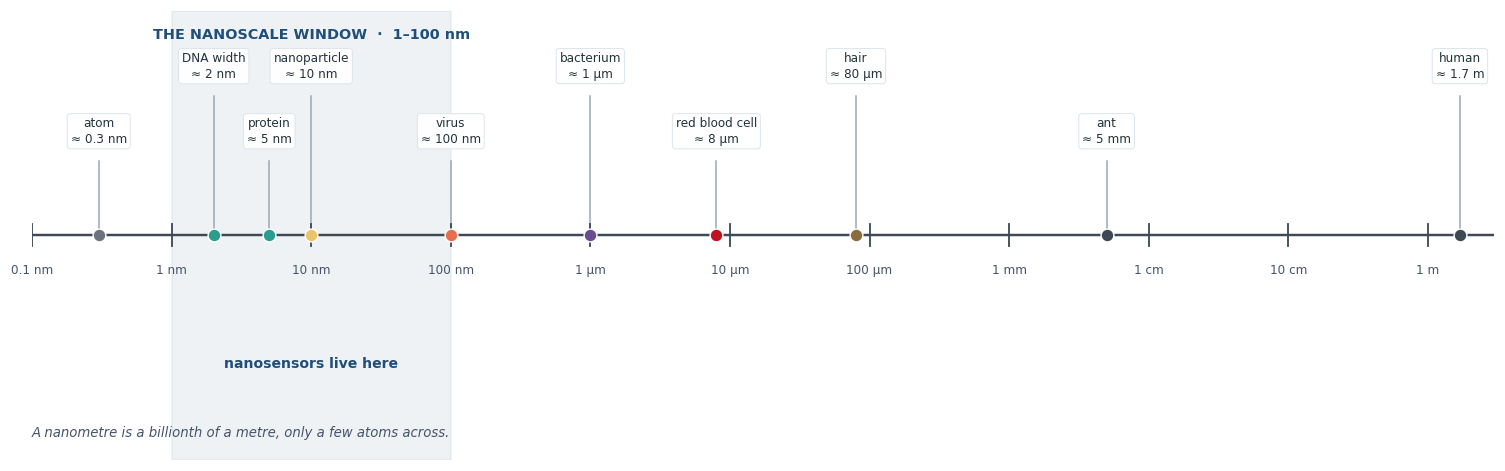

In [12]:
fig, ax = plt.subplots(figsize=(13.8, 4.4))
ax.set_xscale("log")
ax.set_xlim(1e-10, 3e0)
ax.set_ylim(-1.45, 1.45)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
ax.set_yticks([])
ax.set_xticks([])
ax.grid(True, axis="x", alpha=0.18)

# nanoscale window
ax.axvspan(1e-9, 1e-7, color=PALETTE["blue"], alpha=0.07, zorder=0)
ax.text(1e-8, 1.34, "THE NANOSCALE WINDOW  ·  1–100 nm", ha="center", va="top",
        fontsize=9.4, color=PALETTE["blue"], fontweight="bold")

# axis line
ax.plot([1e-10, 3e0], [0, 0], color="#3d4a55", lw=1.6, zorder=2)

# decade ticks
decades = [(1e-10, "0.1 nm"), (1e-9, "1 nm"), (1e-8, "10 nm"), (1e-7, "100 nm"),
           (1e-6, "1 µm"), (1e-5, "10 µm"), (1e-4, "100 µm"), (1e-3, "1 mm"),
           (1e-2, "1 cm"), (1e-1, "10 cm"), (1e0, "1 m")]
for x, lab in decades:
    ax.plot([x, x], [-0.07, 0.07], color="#3d4a55", lw=1.2)
    ax.text(x, -0.18, lab, ha="center", va="top", fontsize=7.9, color="#44546a")

objects = [
    (3e-10, "atom\n≈ 0.3 nm", PALETTE["gray"]),
    (2e-9, "DNA width\n≈ 2 nm", PALETTE["teal"]),
    (5e-9, "protein\n≈ 5 nm", PALETTE["teal"]),
    (1e-8, "nanoparticle\n≈ 10 nm", PALETTE["gold"]),
    (1e-7, "virus\n≈ 100 nm", PALETTE["coral"]),
    (1e-6, "bacterium\n≈ 1 µm", PALETTE["violet"]),
    (8e-6, "red blood cell\n≈ 8 µm", PALETTE["red"]),
    (8e-5, "hair\n≈ 80 µm", "#8a6d3b"),
    (5e-3, "ant\n≈ 5 mm", "#3d4a55"),
    (1.7, "human\n≈ 1.7 m", "#3d4a55"),
]
lanes = [0.58, 1.00, 0.58, 1.00, 0.58, 1.00, 0.58, 1.00, 0.58, 1.00]
for i, (size, label, col) in enumerate(objects):
    lane = lanes[i]
    ax.plot([size, size], [0, lane - 0.10], color="#9aa8b6", lw=1.0, zorder=1)
    ax.scatter([size], [0], s=70, color=col, edgecolor="white",
               linewidth=0.9, zorder=5)
    ax.text(size, lane, label, ha="center", va="bottom", fontsize=7.9,
            color=PALETTE["ink"], linespacing=1.25, zorder=6,
            bbox=dict(boxstyle="round,pad=0.28", facecolor="white",
                      edgecolor="#dde5ec", linewidth=0.7, alpha=0.95))

ax.annotate("nanosensors live here", xy=(1e-8, 0.04), xytext=(1e-8, -0.78),
            ha="center", va="top", fontsize=9.2, color=PALETTE["blue"],
            fontweight="bold",)
            #arrowprops=dict(arrowstyle="->", lw=1.4, color=PALETTE["blue"]))

ax.text(1e-10, -1.30,
        "A nanometre is a billionth of a metre, only a few atoms across." ,
        fontsize=8.7, color="#44546a", style="italic", linespacing=1.45)

fig.tight_layout()
save_fig(fig, "fig_1_6_scale_ladder")
plt.show()

<p style="text-align:center; font-size:0.92em; color:#555; margin-top:-6px;">
<b>Figure 1.6: The scale ladder.</b> From a single atom to a human, on a logarithmic axis. The shaded band (1&ndash;100 nm) is the nanosensor window. Its lower edge is the size of a small molecule; its upper edge is the size of a virus. Image not to scale in the vertical direction, obviously.
</p>

### 6.2 Why the nanoscale changes the rules

Shrinking a sensor to the nanoscale changes five things at once. Each of them is a physical scaling law, and each is exploited by a different family of nanosensors.

#### (a) Surfaces dominate volumes

For a sphere of radius $r$, the surface area is $4\pi r^2$ and the volume is $\tfrac{4}{3}\pi r^3$, so the **surface-to-volume ratio** is

$$ \frac{A}{V} = \frac{3}{r} $$

The ratio scales as $1/r$: halve the size and you double the surface area per unit volume. A 10&nbsp;nm nanoparticle has a hundred times the surface-to-volume ratio of a 1&nbsp;&micro;m particle, and a hundred thousand times that of a 1&nbsp;mm bead.

The consequence is that in a nanomaterial, **a large fraction of all the atoms sit at or near the surface.** A surface atom has fewer neighbours, is less tightly bound, and is chemically more reactive than a bulk atom. This is why nanocatalysts are so active, why the melting point of a nanoparticle is lower than that of the bulk metal, and, crucially for us, why **almost every atom in a nanosensor can participate in sensing**. In a bulk sensor, the analyte interacts only with the surface; the interior is dead weight. In a nanosensor, the interior is barely there.

This is also the basis of the huge **specific surface area** of nanomaterials: a gram of porous nanomaterial can have a surface area of hundreds or thousands of square metres, which is why it can adsorb, react with or bind a large amount of analyte per unit mass.

In [13]:
def surface_to_volume_demo(radius_nm=10, shell_nm=0.5):
    '''Why the nanoscale is surface-dominated: A/V ratio and surface-atom fraction.'''
    r = np.logspace(0, 3, 600)                 # nm
    av = 3.0 / r                                # nm^-1
    frac = np.where(r > shell_nm, 1.0 - ((r - shell_nm) / r) ** 3, 1.0)

    av_now = 3.0 / radius_nm
    frac_now = 1.0 - max(radius_nm - shell_nm, 0.0) ** 3 / radius_nm ** 3
    bulk_ratio = 1000.0 / radius_nm             # A/V relative to a 1 µm particle

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.9))

    # ---------------------------------------------------------------- left: A/V
    ax1.loglog(r, av, color=PALETTE["blue"], lw=2.8, zorder=2)
    for xm, lab in [(2, "2 nm"), (10, "10 nm"), (100, "100 nm"), (1000, "1 µm")]:
        ax1.scatter([xm], [3.0 / xm], s=55, color="#3d4a55", zorder=4)
    ax1.scatter([radius_nm], [av_now], s=170, color=PALETTE["gold"],
                edgecolor="black", linewidth=1.3, zorder=6)
    ax1.annotate(f"r = {radius_nm:.0f} nm\nA/V = {av_now:.3f} nm$^{-1}$",
                 (radius_nm, av_now), xytext=(14, 16), textcoords="offset points",
                 fontsize=9.0, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                           edgecolor="#b8c4d0", alpha=0.95))
    ax1.set_xlabel("particle radius r (nm)")
    ax1.set_ylabel("surface-to-volume ratio  A/V  (nm$^{-1}$)")
    ax1.set_title("Surfaces per unit volume: A/V = 3/r")
    ax1.set_xlim(1, 1000)
    style_axes(ax1)
    ax1.text(0.97, 0.96, "straight line on a log–log plot\n= a pure 1/r scaling law",
             transform=ax1.transAxes, ha="right", va="top", fontsize=8.2,
             color=PALETTE["gray"], style="italic")

    # ---------------------------------------------------------------- right: surface atoms
    ax2.semilogx(r, 100 * frac, color=PALETTE["teal"], lw=2.8, zorder=2)
    ax2.axvspan(1, 10, color=PALETTE["teal"], alpha=0.07, zorder=0)
    ax2.axvspan(100, 1000, color=PALETTE["gray"], alpha=0.05, zorder=0)
    ax2.scatter([radius_nm], [100 * frac_now], s=170, color=PALETTE["gold"],
                edgecolor="black", linewidth=1.3, zorder=6)
    ax2.annotate(f"{100 * frac_now:.0f}% at the surface",
                 (radius_nm, 100 * frac_now), xytext=(14, 12),
                 textcoords="offset points", fontsize=9.0, fontweight="bold",
                 bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                           edgecolor="#b8c4d0", alpha=0.95))
    ax2.set_xlabel("particle radius r (nm)")
    ax2.set_ylabel("atoms within a shell of thickness δ (%)")
    ax2.set_title("Surface atoms as a fraction of the total")
    ax2.set_xlim(1, 1000)
    ax2.set_ylim(0, 105)
    style_axes(ax2)
    ax2.text(1.25, 101, "surface-dominated", fontsize=8.2, color=PALETTE["teal"])
    ax2.text(240, 7, "bulk-like", fontsize=8.2, color=PALETTE["gray"])

    if radius_nm >= 100:
        verdict = "BULK-LIKE: the surface is a small correction; most atoms are interior."
    elif radius_nm >= 10:
        verdict = "NANOSCALE: the surface matters a lot — this is the useful middle ground."
    else:
        verdict = "SURFACE-DOMINATED: most atoms are at the surface; surface chemistry IS the sensor."

    diag = (
        "--- Surface-to-volume diagnostics ---\n"
        f"Radius r = {radius_nm:.0f} nm      Shell thickness δ = {shell_nm:.2f} nm      Surface-atom fraction ≈ {100 * frac_now:.0f}%\n"
        f"A/V = {av_now:.3f} per nm = {av_now * 1e9:.2e} per m      Compared with a 1 µm particle: {bulk_ratio:.0f}× more surface per volume\n"
        f"Verdict: {verdict}"
    )
    fig.tight_layout(rect=(0, 0.19, 1, 1))
    diagnostic_box(fig, diag, y=0.010, fontsize=8.9)
    save_fig(fig, "int_9_surface_to_volume")
    plt.show()

interact(
    surface_to_volume_demo,
    radius_nm=FloatSlider(min=1, max=1000, step=1, value=10,
                          description="Particle radius (nm):",
                          style={"description_width": "initial"},
                          layout=Layout(width="56%"), continuous_update=False),
    shell_nm=FloatSlider(min=0.2, max=1.0, step=0.05, value=0.5,
                         description="Surface shell thickness δ (nm):",
                         style={"description_width": "initial"},
                         layout=Layout(width="56%"), continuous_update=False),
);

interactive(children=(FloatSlider(value=10.0, continuous_update=False, description='Particle radius (nm):', la…

> **What to notice**
>
> - **The scaling is brutal.** Going from 1&nbsp;&micro;m to 10&nbsp;nm multiplies the surface-to-volume ratio by 100. This is why nanomaterial sensors can respond to much smaller amounts of analyte: there is simply more surface available per unit mass.
> - **The surface fraction is not the same as A/V.** A/V is a geometric ratio; the fraction of *atoms* near the surface depends on the shell thickness δ, which is roughly one atomic layer (0.2&ndash;0.5&nbsp;nm). For a 2&nbsp;nm particle, nearly all atoms are within δ of the surface.
> - **The same physics that gives sensitivity also gives noise.** A surface-dominated sensor is sensitive not only to the analyte but to everything else that sticks to the surface. Surface area cuts both ways; this is a theme we will return to in the limitations.
> - **The "useful" nanoscale is not the smallest possible.** There is a trade-off between surface fraction and structural stability: a 1&nbsp;nm particle is almost all surface, but it may be unstable, dissolve, or lose its crystal structure. The 10&ndash;100&nbsp;nm range is often the practical sweet spot.

#### (b) Quantum confinement

The second scaling law is quantum mechanical. An electron in a piece of semiconductor behaves as a wave whose wavelength depends on the material, typically a few nanometres. When a particle is made smaller than that wavelength, the electron can no longer move freely in all directions: it is **confined**, and its allowed energy levels become discrete.

The simplest model of this is the **Brus equation** for a spherical semiconductor nanocrystal of radius $r$:

$$ E_g(r) \approx E_{g,\text{bulk}} + \frac{h^2}{8\mu r^2} - \frac{1.786\,e^2}{4\pi\varepsilon_0\varepsilon_r r} $$

The first term is the bulk bandgap; the second is the confinement energy (which grows as $1/r^2$); the third is the Coulomb attraction between the confined electron and hole (which grows as $1/r$). The particle's diameter is $d = 2r$. The practical consequence is dramatic: **the smaller the crystal, the larger the bandgap, and the bluer the light it emits.** A single material, cadmium selenide, for example, can be made to fluoresce across the entire visible spectrum simply by changing the particle size.

These particles are called **quantum dots**. They are the clearest example of a nanosensor material whose optical properties are designed by size rather than by chemistry.

In [17]:
def quantum_dot_demo(diameter=4.0):
    '''CdSe quantum dot: size sets the bandgap, the bandgap sets the colour.'''
    E_bulk = 1.74          # eV, bulk CdSe bandgap
    mu_eff = 0.25          # effective reduced mass (model parameter, in units of m_e)
    eps_r = 10.0           # relative permittivity
    h2_8m0 = 0.376         # h^2/(8 m_e) in eV·nm^2

    def bandgap(d):
        r = d / 2.0        # Brus equation uses the particle radius
        confinement = h2_8m0 / (mu_eff * r ** 2)
        coulomb = 1.786 * 1.44 / (eps_r * r)     # 1.44 eV·nm = e^2/(4πε0)
        return E_bulk + confinement - coulomb

    d_axis = np.linspace(2, 10, 500)
    Eg_axis = bandgap(d_axis)
    lam_axis = 1240.0 / Eg_axis

    Eg = bandgap(diameter)
    lam = 1240.0 / Eg
    colour = wavelength_to_rgb(lam)
    shift_meV = 1000.0 * (Eg - E_bulk)

    def colour_name(wl):
        if wl < 450:
            return "violet"
        if wl < 495:
            return "blue"
        if wl < 570:
            return "green"
        if wl < 590:
            return "yellow"
        if wl < 625:
            return "orange"
        return "red"

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.4, 4.9))

    # ---------------------------------------------------------------- left: size -> colour
    ax1.plot(d_axis, lam_axis, color=PALETTE["blue"], lw=2.8, zorder=2)
    ax1.scatter([diameter], [lam], s=170, color=colour, edgecolor="black",
                linewidth=1.3, zorder=6)
    ax1.set_xlim(2, 10)
    ax1.set_ylim(390, 730)
    ax1.set_xlabel("quantum-dot diameter (nm)")
    ax1.set_ylabel("emission wavelength λ (nm)")
    ax1.set_title("Size sets the colour")
    style_axes(ax1)
    ax1.annotate(f"d = {diameter:.1f} nm\nλ = {lam:.0f} nm",
                 (diameter, lam), xytext=(5.9, 500),
                 fontsize=9.2, fontweight="bold", ha="left", va="center",
                 bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                           edgecolor="#b8c4d0", alpha=0.95),
                 arrowprops=dict(arrowstyle="->", lw=1.0, color="#8a99a8"))
    ax1.text(2.15, 722, "smaller → higher bandgap → bluer", fontsize=8.4,
             color=PALETTE["gray"], style="italic", va="top")

    # ---------------------------------------------------------------- right: spectrum
    wl = np.linspace(400, 780, 600)
    spec = np.exp(-0.5 * ((wl - lam) / 28.0) ** 2)
    ax2.fill_between(wl, 0, spec, color=colour, alpha=0.65, zorder=2)
    ax2.plot(wl, spec, color=PALETTE["ink"], lw=2.0, zorder=3)
    ax2.axvline(lam, color=PALETTE["gray"], ls=":", lw=1.2)
    ax2.set_xlim(400, 780)
    ax2.set_ylim(0, 1.12)
    ax2.set_xlabel("wavelength (nm)")
    ax2.set_ylabel("photoluminescence (a.u.)")
    ax2.set_title("What the detector sees")
    style_axes(ax2)
    lum = 0.2126 * colour[0] + 0.7152 * colour[1] + 0.0722 * colour[2]
    ax2.text(0.03, 0.95, f"emitted colour: {colour_name(lam)}",
             transform=ax2.transAxes, ha="left", va="top", fontsize=8.8,
             fontweight="bold", color="white" if lum < 0.55 else "#22333b",
             bbox=dict(boxstyle="round,pad=0.4", facecolor=colour,
                       edgecolor="#3d4a55", linewidth=1.0))

    diag = (
        "--- Quantum-dot diagnostics ---\n"
        f"Diameter d = {diameter:.1f} nm      Bandgap Eg = {Eg:.3f} eV      Emission λ = {lam:.0f} nm ({colour_name(lam)})\n"
        f"Confinement shift relative to bulk CdSe: {shift_meV:+.0f} meV (bulk Eg = {E_bulk:.2f} eV ≈ 713 nm)\n"
        "Smaller dots are bluer because the electron and hole are confined more tightly; this is the same physics that makes\n"
        "quantum dots useful as size-tunable fluorescent labels. The model is the Brus effective-mass approximation — real dots differ."
    )
    fig.tight_layout(rect=(0, 0.20, 1, 1))
    diagnostic_box(fig, diag, y=0.010, fontsize=8.8)
    save_fig(fig, "int_10_quantum_dots")
    plt.show()

interact(
    quantum_dot_demo,
    diameter=FloatSlider(min=2.0, max=10.0, step=0.1, value=4.0,
                         description="Quantum-dot diameter (nm):",
                         style={"description_width": "initial"},
                         layout=Layout(width="56%"), continuous_update=False),
);

interactive(children=(FloatSlider(value=4.0, continuous_update=False, description='Quantum-dot diameter (nm):'…

> **What to notice**
>
> - **Size is a design parameter.** No chemistry changes between a blue dot and a red dot of the same material, only the diameter. This is a quintessentially nanoscale form of engineering.
> - **The tuning range is large.** Across 2&ndash;10&nbsp;nm, the emission sweeps from violet to deep red: more than an electron volt of bandgap, controlled by a few nanometres of material.
> - **The model is a caricature.** Real quantum dots have surface states, size distributions, ligands and non-radiative pathways; the Brus equation gets the *trend* right, not the exact colour. This is a good habit to develop: every model in this book is a simplification, and the useful question is always "which trend does it capture?"


#### (c) Short diffusion lengths mean fast response

A sensor cannot respond faster than the analyte can reach its sensing surface. Diffusion sets a characteristic time that scales as the *square* of the distance:

$$ t \sim \frac{L^2}{2D} $$

where $L$ is the diffusion distance and $D$ the diffusion coefficient. Reducing the relevant length from a millimetre to 100&nbsp;nm reduces the diffusion time by a factor of $10^8$. This is why nanoscale sensors can respond in seconds or milliseconds while bulk sensors take minutes or hours; it is also why the *response time* column of a datasheet often improves dramatically when a sensing layer is nanostructured.

#### (d) The single-molecule regime

When the sensing volume is itself a few nanometres, the arrival of a single molecule becomes a measurable event. There is no longer any need to average over a large population: the sensor can count. A nanopore, for example, has a sensing volume of a few cubic nanometres; a single DNA molecule entering the pore blocks a measurable fraction of the ionic current, producing a discrete, detectable pulse.

At this limit, the distinction between "concentration" and "events" blurs. A sensor that reports individual binding events has an effective limit of detection that can be far below what any ensemble measurement could reach, because the bottleneck is no longer signal averaging, but the probability that the molecule arrives at all.

#### (e) Nanostructures concentrate light

Finally, nanostructures interact with light in ways that bulk materials do not. Metal nanoparticles host **localised surface plasmons**: collective oscillations of conduction electrons that resonantly absorb and scatter light at a colour determined by size, shape and environment. At the surface of a plasmonic nanostructure, the local electric field can be enhanced by factors of 100 or more, which is the basis of **surface-enhanced Raman scattering (SERS)** and of single-molecule optical detection.

We will meet these effects again in the future. For now, the point is that at the nanoscale, light, electrons and molecules all interact in the same small volume, which is precisely what a sensor needs.

### 6.3 The nanomaterial toolbox

Nanosensors are built from a surprisingly small set of material families, classified by **dimensionality**: how many of their dimensions are larger than a few nanometres. Dimensionality is not a cosmetic label; it determines surface area, electronic transport, mechanical stiffness and optical response.

*Figure 1.7 summarises the four families and gives their most common sensing role.*

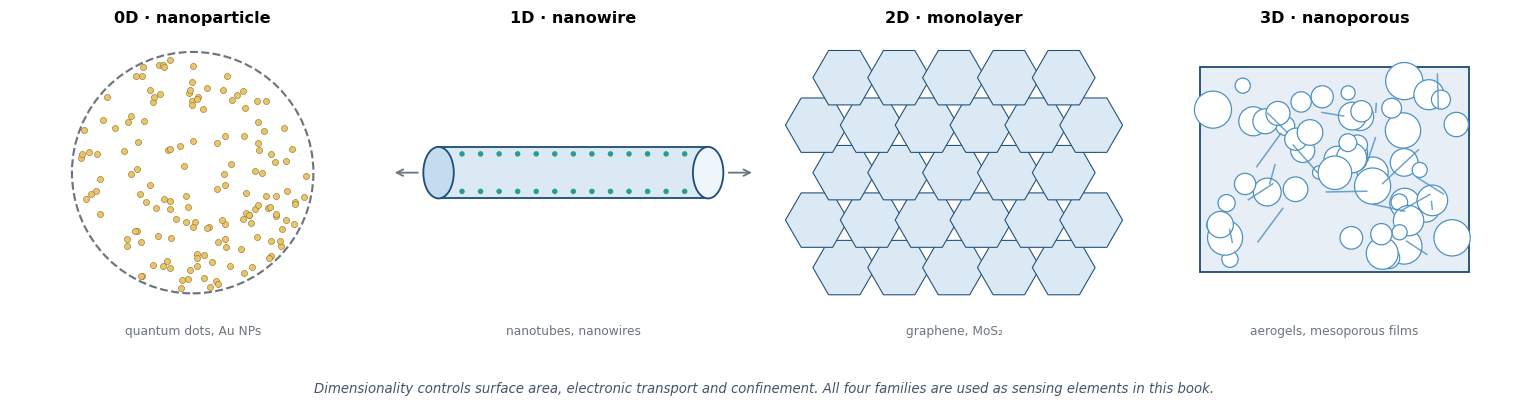

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(14.0, 3.7))
for ax in axes:
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_xlim(-1.55, 1.55)
    ax.set_ylim(-1.35, 1.15)

# ---------------------------------------------------------------- 0D: nanoparticle
ax = axes[0]
rng = np.random.default_rng(4)
n = 150
rr = np.sqrt(rng.random(n))
th = 2 * np.pi * rng.random(n)
ax.scatter(rr * np.cos(th), rr * np.sin(th), s=16, color=PALETTE["gold"],
           edgecolor="#8a6d1a", linewidth=0.35, zorder=3)
ax.add_patch(Circle((0, 0), 1.03, fill=False, lw=1.4, ls="--",
                    color=PALETTE["gray"], zorder=2))
ax.set_title("0D · nanoparticle", fontsize=10.5)
ax.text(0, -1.30, "quantum dots, Au NPs", ha="center", va="top", fontsize=8.0,
        color=PALETTE["gray"])

# ---------------------------------------------------------------- 1D: nanowire / nanotube
ax = axes[1]
ax.add_patch(Rectangle((-1.15, -0.22), 2.30, 0.44, facecolor="#dbe9f4",
                       edgecolor=PALETTE["blue"], lw=1.2, zorder=2))
ax.add_patch(Ellipse((-1.15, 0.0), 0.26, 0.44, facecolor="#c5dbee",
                     edgecolor=PALETTE["blue"], lw=1.2, zorder=3))
ax.add_patch(Ellipse((1.15, 0.0), 0.26, 0.44, facecolor="#eef5fb",
                     edgecolor=PALETTE["blue"], lw=1.2, zorder=3))
for x in np.linspace(-0.95, 0.95, 13):
    ax.scatter([x, x], [0.16, -0.16], s=13, color=PALETTE["teal"],
               edgecolor="none", zorder=4)
ax.annotate("", xy=(-1.55, 0), xytext=(-1.30, 0),
            arrowprops=dict(arrowstyle="->", lw=1.2, color=PALETTE["gray"]))
ax.annotate("", xy=(1.55, 0), xytext=(1.30, 0),
            arrowprops=dict(arrowstyle="->", lw=1.2, color=PALETTE["gray"]))
ax.set_title("1D · nanowire", fontsize=10.5)
ax.text(0, -1.30, "nanotubes, nanowires", ha="center", va="top", fontsize=8.0,
        color=PALETTE["gray"])

# ---------------------------------------------------------------- 2D: honeycomb sheet
ax = axes[2]
for row in range(-3, 4):
    for col in range(-3, 4):
        x = col * 0.468 + (row % 2) * 0.234
        y = row * 0.405
        if -1.28 < x < 1.28 and -0.86 < y < 0.86:
            ax.add_patch(RegularPolygon((x, y), numVertices=6, radius=0.268,
                                        orientation=np.pi / 6,
                                        facecolor="#dbe9f4", edgecolor=PALETTE["blue"],
                                        linewidth=0.7, zorder=2))
ax.set_title("2D · monolayer", fontsize=10.5)
ax.text(0, -1.30, "graphene, MoS₂", ha="center", va="top", fontsize=8.0,
        color=PALETTE["gray"])

# ---------------------------------------------------------------- 3D: porous network
ax = axes[3]
rng = np.random.default_rng(9)
ax.add_patch(Rectangle((-1.15, -0.85), 2.30, 1.75, facecolor="#e7eef5",
                       edgecolor=PALETTE["blue"], lw=1.2, zorder=1))
for _ in range(55):
    px = rng.uniform(-1.05, 1.05)
    py = rng.uniform(-0.75, 0.80)
    pr = rng.uniform(0.05, 0.16)
    ax.add_patch(Circle((px, py), pr, facecolor="white",
                        edgecolor=PALETTE["sky"], linewidth=0.8, zorder=2))
for _ in range(18):
    p0 = (rng.uniform(-1.0, 1.0), rng.uniform(-0.7, 0.75))
    p1 = (p0[0] + rng.uniform(-0.35, 0.35), p0[1] + rng.uniform(-0.30, 0.30))
    ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color=PALETTE["sky"], lw=1.0,
            alpha=0.8, zorder=3)
ax.set_title("3D · nanoporous", fontsize=10.5)
ax.text(0, -1.30, "aerogels, mesoporous films", ha="center", va="top",
        fontsize=8.0, color=PALETTE["gray"])

fig.text(0.5, 0.015,
         "Dimensionality controls surface area, electronic transport and confinement. All four families are used as sensing elements in this book.",
         ha="center", va="bottom", fontsize=8.7, color="#44546a", style="italic")
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_fig(fig, "fig_1_7_dimensionality")
plt.show()

<p style="text-align:center; font-size:0.92em; color:#555; margin-top:-6px;">
<b>Figure 1.7: The four dimensions of nanomaterials.</b> 0D particles confine electrons in all three directions (quantum dots); 1D wires and tubes confine electrons in two directions and provide a direct conduction path; 2D monolayers are all surface and confine electrons in one direction; 3D nanoporous networks maximise accessible surface area. Every family appears in a different kind of nanosensor.
</p>

A few of these materials deserve a sentence each, because they recur throughout the book:

- **Gold and silver nanoparticles.** Chemically inert, easy to functionalise, and strongly plasmonic. Their colour depends on size, shape and local refractive index, which makes them the basis of simple colorimetric assays and of LSPR biosensors.
- **Quantum dots.** Semiconductor nanocrystals with size-tunable fluorescence. Excellent labels for imaging and multiplexed detection, though their toxicity (often cadmium-based) is a real concern.
- **Nanowires and nanotubes.** A 1D conduction channel whose conductance is exquisitely sensitive to charges or molecules bound on its surface. Silicon nanowire field-effect sensors can detect proteins at picomolar concentrations, and optimised devices reach femtomolar levels.
- **2D materials (graphene, MoS$_2$, etc.).** Every atom is a surface atom, so binding events have a large effect on the electronic properties; graphene's high mobility makes it attractive for fast, low-noise sensors.
- **Nanoporous materials and nanostructured electrodes.** High surface area plus short diffusion paths; the workhorses of electrochemical sensing.

### 6.4 How a nanosensor transduces

Whatever the material, a nanosensor must convert a nanoscale recognition event into a measurable signal. They are the nanoscale versions of the physical/chemical classification from Section 2.





| Transduction | Physical signal | Nanoscale element | Typical target | 
|---|---|---|---|
| **Ionic-current blockade** | pA current pulses | Nanopore (1&ndash;50&nbsp;nm) | DNA, RNA, proteins | 
| **Field-effect / conductance** | conductance change | Nanowire, nanotube, 2D sheet | Ions, proteins, gases | 
| **Localised plasmon resonance** | wavelength/intensity shift | Au/Ag nanoparticle | Binding events, refractive index |
| **Surface-enhanced Raman** | vibrational spectrum | Plasmonic hot-spot | Chemical fingerprint |
| **Fluorescence / FRET** | colour and intensity | Quantum dot, dye pair | Biomolecular interactions |
| **Mechanical resonance** | frequency shift | Nanocantilever, nanobeam | Mass, force, binding |
| **Electrochemical** | current or potential | Nanostructured electrode | Glucose, metabolites, ions |


### 6.5 So what makes a sensor a "nanosensor"?

There is no single, universally agreed definition, but three criteria capture how the term is used in practice:

1. **A critical dimension is nanoscale.** At least one dimension of the sensing element or transducer, the thickness of a wire, the diameter of a pore, the size of a particle, lies in the 1&ndash;100&nbsp;nm range.
2. **The operation relies on nanoscale physics or chemistry.** Surface dominance, quantum confinement, single-molecule transport, plasmonic field enhancement or nanomechanical resonance must be part of *why the sensor works*.
3. **The nanoscale buys something measurable.** Sensitivity, speed, selectivity, or a genuinely new capability (single-molecule detection, label-free operation, multiplexing) that a bulk device cannot deliver.

A useful counter-example: a conventional electrode coated with a thin nanostructured film is *nanostructured* but may still be a bulk sensor if its selectivity and sensitivity come from the electrode area rather than from nanoscale physics. The term "nanosensor" is best reserved for devices where the nanoscale is doing real work.

### 6.6 The price of going nano

Nanosensors are not automatically better. The same surface dominance that makes them sensitive makes them vulnerable, and the gap between a beautiful result in a paper and a reliable product is often enormous.

- **Fabrication variability.** Bottom-up synthesis produces particles with a distribution of sizes and shapes; top-down fabrication produces devices with device-to-device variation. A sensor whose response depends on a 5&nbsp;nm feature is only as reproducible as that feature.
- **Drift and fouling.** A high-surface-area sensor adsorbs everything, not just the target. Proteins coat surfaces within seconds in blood or serum; the sensor's baseline drifts and its selectivity degrades. Antifouling coatings and reference channels are essential.
- **Debye screening.** In a biological fluid, mobile ions screen electric fields over a distance of less than a nanometre (the Debye length). A field-effect sensor must therefore have its recognition element *within* that distance, or the target's charge is invisible. This is a fundamental limit, not a design flaw to be engineered away.
- **Functionalisation reproducibility.** Attaching the right receptor, at the right density, in the right orientation, is harder on a nanoparticle than on a macroscopic surface, and much harder to verify.
- **Scale-up and standardisation.** Making one device in a clean room is not the same as making a million with a specification. Reference materials, calibration protocols and regulatory pathways for nanoscale devices are still maturing.
- **Environmental, health and safety questions.** Some of the most useful nanomaterials (e.g., cadmium-based quantum dots, silver nanoparticles) raise toxicity and environmental concerns that must be designed around.

> **The honest summary.** Nanoscale sensing trades *sensitivity and speed* for *reproducibility, stability and manufacturability*. The research frontier is largely about winning back the second group without giving up the first. When you read a paper claiming a record-breaking nanosensor, the interesting questions are always: how many devices did you make? how long did it last? what happens in a real sample? and how does it compare on cost?

### 6.7 Where this book goes next

We now have the vocabulary and the toolbox. The rest of the book applies them.

The measurement chain from Figure 1.1 still applies, it just gets shorter, faster and more sensitive. The metrics from Section 3 still apply, they just become harder to satisfy. And the public-health lesson from Section 5 still applies: the value of a sensor is realised only when it is deployed, trusted and acted upon.



## Chapter summary

### The ten ideas worth keeping

1. **A sensor is not a device.** The sensor is the element that touches the world and converts a stimulus into a signal; the device powers, reads, digitises, calibrates and interprets it. Both can fail, and they fail differently.
2. **A measurement is a chain, not a number.** Recognition &rarr; transduction &rarr; conditioning &rarr; digitisation &rarr; processing &rarr; decision. The measurement is only as good as its weakest link.
3. **Chemical vs. physical is a classification of the stimulus and the recognition mechanism, not of the electronics.** Almost everything ends up as a voltage; what differs is whether a molecule or a physical quantity is being recognised.
4. **Sensitivity is a slope, not a figure of merit.** A steep calibration curve through a noisy, drifting baseline can be worse than a shallow one that is rock-steady. What matters is signal-to-noise.
5. **The limit of detection is set by noise divided by sensitivity.** $LoD \approx 3\sigma_{\text{blank}}/m$. The dynamic range runs from the LoD to the saturation point, and confusing the three regimes (below LoD, linear, saturated) is a classic experimental error.
6. **Sensitivity without selectivity is dangerous.** A sensor that cannot tell the target from an interferent reports a wrong answer with the same confidence as a right one. The almond-versus-cyanide problem.
7. **Accuracy and precision are different failures with different fixes.** Bias is removed by calibration; scatter is reduced by averaging or better hardware. RMSE combines both, so quoting it alone hides the diagnosis.
8. **Sensors are infrastructure.** They extend where we can explore, reveal systems too large to see, and feed the models, and the models are only as good as the data (GIGO). In public health, early detection literally flattens the curve.
9. **The nanoscale changes the physics.** Surfaces dominate volumes ($A/V = 3/r$), electrons become confined (quantum dots), diffusion becomes fast, single molecules become countable, and plasmons concentrate light. That is why nanosensors can do things bulk sensors cannot.
10. **Nano is not automatically better.** Reproducibility, drift, fouling, Debye screening, functionalisation and scale-up all become harder at the nanoscale. The frontier is about keeping the sensitivity while winning back the reliability.

### The chapter in one sentence

> A sensor turns a physical or chemical stimulus into a signal, a device turns that signal into knowledge, and a nanosensor does the same thing at a scale where single molecules and surfaces, rather than bulk averages, decide what can be measured.

### Key equations

| Concept | Equation | What it tells you |
|---|---|---|
| Sensitivity | $S = \dfrac{dY}{dX} \approx m$ | Slope of the calibration curve; output per unit input |
| Limit of detection | $LoD = \dfrac{3\sigma_{\text{blank}}}{m}$ | Smallest concentration distinguishable from noise |
| Limit of quantification | $LoQ \approx \dfrac{10\sigma_{\text{blank}}}{m}$ | Smallest concentration that can be quantified |
| Total error | $RMSE = \sqrt{b^2 + \sigma^2}$ | Combines systematic bias $b$ and random scatter $\sigma$ |
| Surface-to-volume | $\dfrac{A}{V} = \dfrac{3}{r}$ | Why small particles are surface-dominated |
| FRET efficiency | $E = \dfrac{1}{1 + (r/R_0)^6}$ | A molecular ruler over 1&ndash;10&nbsp;nm |
| Quantum confinement | $E_g(r) \approx E_{g,\text{bulk}} + \dfrac{h^2}{8\mu r^2} - \dfrac{1.786e^2}{4\pi\varepsilon_0\varepsilon_r r}$ | Why quantum-dot colour depends on size |
| Diffusion time | $t \sim \dfrac{L^2}{2D}$ | Why nanoscale sensors respond faster |

### Self-check questions

Work through these before moving to Chapter 2. Click an answer to reveal it; try to answer first.

<details>
<summary><b>Q1.</b> A smartphone contains an accelerometer, a microphone and a fingerprint reader. For each, identify the sensor and one thing the device does with its signal.</summary>
<p><b>Answer.</b> Accelerometer: a MEMS proof mass whose displacement is read capacitively; the device filters the three-axis signal, detects steps and rotates the screen. Microphone: a MEMS diaphragm whose capacitance changes with sound pressure; the device amplifies, digitises, filters and encodes the audio. Fingerprint reader: a capacitive (or optical/ultrasonic) array that images ridge patterns; the device extracts minutiae, matches them against stored templates and makes an authentication decision. In every case the sensor produces an analogue signal; the device turns it into a decision.</p>
</details>

<details>
<summary><b>Q2.</b> Classify as chemical or physical: (a) a thermocouple, (b) an enzyme glucose electrode, (c) a pH indicator dye, (d) a piezoresistive pressure sensor, (e) a gold-nanoparticle colourimetric test.</summary>
<p><b>Answer.</b> (a) Physical (thermoelectric voltage from a temperature gradient). (b) Chemical (enzyme recognition of glucose, electrochemical read-out). (c) Chemical (protonation state changes the dye's optical properties). (d) Physical (strain changes resistance). (e) Chemical in its recognition (binding or aggregation driven by the target), physical in its transduction (plasmonic colour change) &mdash; a good example of why the boundary is blurry.</p>
</details>

<details>
<summary><b>Q3.</b> Sensor A has twice the sensitivity of sensor B but three times the noise. Which has the lower limit of detection?</summary>
<p><b>Answer.</b> Sensor B. LoD is proportional to noise divided by sensitivity: LoD<sub>A</sub>/LoD<sub>B</sub> = (3/2) = 1.5, so sensor A's LoD is 50% higher (worse). Sensitivity alone tells you nothing about detection limits.</p>
</details>

<details>
<summary><b>Q4.</b> A sensor has a sensitivity of 2&nbsp;mV per &micro;M, a blank noise of 0.5&nbsp;mV, and saturates at 40&nbsp;mV. Estimate the LoD, the LoQ and the linear range.</summary>
<p><b>Answer.</b> LoD = 3&nbsp;&times;&nbsp;0.5/2 = 0.75&nbsp;&micro;M. LoQ = 10&nbsp;&times;&nbsp;0.5/2 = 2.5&nbsp;&micro;M. Saturation occurs at 40/2 = 20&nbsp;&micro;M. Linear range: roughly 0.75&ndash;20&nbsp;&micro;M, i.e. a dynamic range factor of about 27.</p>
</details>

<details>
<summary><b>Q5.</b> A sensor reads a 5&nbsp;nM target in the presence of a 100&nbsp;nM interferent with a selectivity coefficient of 0.02. What does it report, and what is the relative error?</summary>
<p><b>Answer.</b> Interferent contribution = 0.02&nbsp;&times;&nbsp;100 = 2&nbsp;nM. Reported value = 5 + 2 = 7&nbsp;nM. Error = +2&nbsp;nM = +40%. That is unacceptable for most quantitative assays: the interferent is spending more than the error budget.</p>
</details>

<details>
<summary><b>Q6.</b> A sensor is precise but inaccurate. What is the most likely cause, and what would you change first? What if it is accurate but imprecise?</summary>
<p><b>Answer.</b> Precise but inaccurate means a systematic error: a calibration offset, a wrong standard, a temperature bias or a drifting reference. Fix the calibration or the reference first &mdash; not the electronics. Accurate but imprecise means random error: noise, insufficient averaging, unstable temperature or sample handling. Average more measurements, improve shielding, or slow down the measurement to reduce noise.</p>
</details>

<details>
<summary><b>Q7.</b> A model trained on sensor data reports R&sup2; = 0.99, but its predictions are wrong. How is that possible, and what should you check?</summary>
<p><b>Answer.</b> R&sup2; measures how well the model fits the data it was trained on, not whether the data are unbiased or representative. The sensors could be miscalibrated, the training range could be narrower than the prediction range (extrapolation), or the training data could be systematically non-representative. Check the residuals, the calibration of the sensors, and performance on held-out data outside the training range.</p>
</details>

<details>
<summary><b>Q8.</b> Explain in one paragraph why earlier detection reduces the peak of an outbreak.</summary>
<p><b>Answer.</b> An outbreak grows roughly exponentially while the fraction of susceptible people is still large. The earlier an intervention reduces transmission, the smaller the number of infections at the moment the growth rate is cut &mdash; and the final peak scales with that number. Intervening one doubling time earlier can roughly halve the peak. Early detection is what allows the intervention to happen earlier; that is why testing and surveillance are public-health tools, not just laboratory procedures.</p>
</details>

<details>
<summary><b>Q9.</b> How much larger is the surface-to-volume ratio of a 5&nbsp;nm particle than that of a 500&nbsp;nm particle?</summary>
<p><b>Answer.</b> A/V scales as 1/r, so the ratio is 500/5 = 100&times;. This is the geometric reason why nanoscale sensing elements can interact with so much more analyte per unit mass.</p>
</details>

<details>
<summary><b>Q10.</b> Why does a smaller quantum dot emit bluer light?</summary>
<p><b>Answer.</b> Confining the electron and hole to a smaller volume raises their kinetic (confinement) energy, which increases the bandgap. A larger bandgap means a higher-energy photon, hence a shorter wavelength &mdash; bluer light. The Brus equation captures this as a 1/r<sup>2</sup> confinement term, where r is the particle radius.</p>
</details>

<details>
<summary><b>Q11.</b> A gold film 50&nbsp;nm thick is used in a surface-plasmon-resonance sensor. Is it a nanosensor? Justify your answer using the three criteria from Section 6.5.</summary>
<p><b>Answer.</b> It is borderline. It has a nanoscale dimension (50&nbsp;nm film thickness), and the plasmon is confined to the metal surface. But the sensing mechanism is a propagating surface plasmon whose resonance depends on the film's optical properties and the surrounding medium, not on a single-molecule or strongly confined nanoscale event; the sensing area is typically square millimetres. By the three criteria it is a *nanostructured optical sensor* but not a nanosensor in the strict sense. If the film is replaced by an array of 50&nbsp;nm gold nanoparticles supporting a localised plasmon (LSPR), the same material becomes a genuine nanosensor: the sensing volume is the particle's near field, and in optimised systems the signal can approach single-molecule sensitivity.</p>
</details>

<details>
<summary><b>Q12.</b> Why is Debye screening a fundamental problem for nanowire field-effect biosensors in blood?</summary>
<p><b>Answer.</b> In a physiological salt solution, mobile ions screen electric fields over a distance of less than about 1&nbsp;nm (the Debye length). A charged target molecule bound further than that from the nanowire surface is electrically invisible to the channel. The sensor can only respond to charges within roughly one Debye length of its surface, which is much smaller than a typical antibody&ndash;antigen complex. Solutions include using short receptors, working at low ionic strength, or using sensing mechanisms that do not rely on long-range electrostatics.</p>
</details>

### Glossary

| Term | Meaning |
|---|---|
| **Analyte** | The specific molecule, ion or species that a sensor is designed to detect or quantify. |
| **Sensor** | The element that interacts with a stimulus and produces a measurable signal. |
| **Transducer** | The physical mechanism that converts one form of energy (chemical, optical, mechanical, thermal) into another (usually electrical). |
| **Device / instrument** | The complete system that powers, reads, digitises, calibrates, displays and communicates the sensor's output. |
| **Calibration** | Establishing the relationship between sensor output and the true value of the stimulus, usually with standards of known concentration. |
| **Sensitivity** | The slope of the calibration curve, $dY/dX$; how much output change per unit input change. |
| **Limit of detection (LoD)** | The lowest concentration distinguishable from the blank noise, conventionally $3\sigma_{\text{blank}}/m$. |
| **Limit of quantification (LoQ)** | The lowest concentration that can be quantified with acceptable uncertainty, often taken as $10\sigma_{\text{blank}}/m$. |
| **Dynamic range** | The concentration interval between the LoD and the upper limit of the sensor. |
| **Selectivity** | The ability to respond to the target analyte rather than to interfering species. |
| **Selectivity coefficient** | The response to an interferent relative to the response to the target at the same concentration. |
| **Accuracy** | Closeness of a measurement to the true value; dominated by systematic bias. |
| **Precision** | Reproducibility of repeated measurements under the same conditions; dominated by random noise. |
| **Bias** | A systematic offset between the measured and true values. |
| **Drift** | A slow change in the sensor's baseline or sensitivity over time. |
| **Hysteresis** | A dependence of the reading on the direction of the change (increasing vs decreasing stimulus). |
| **Fitness for purpose** | The degree to which a sensor's metrics meet the requirements of a specific application. |
| **GIGO** | "Garbage in, garbage out": models and decisions cannot be better than the data that feed them. |
| **Nanoscale** | The size range from roughly 1 to 100&nbsp;nm, where surface, confinement and single-molecule effects dominate. |
| **Surface-to-volume ratio** | Surface area divided by volume; for a sphere it equals $3/r$ and grows as the particle shrinks. |
| **Quantum confinement** | The restriction of electrons to a region comparable to their wavelength, producing discrete energy levels and a size-dependent bandgap. |
| **Quantum dot** | A semiconductor nanocrystal (typically 2&ndash;10&nbsp;nm) whose fluorescence colour is set by its size through quantum confinement. |
| **Plasmon** | A collective oscillation of conduction electrons in a metal, excited by light. |
| **LSPR** | Localised surface plasmon resonance: the plasmon confined to a nanoparticle, producing a colour that depends on size, shape and local refractive index. |
| **SERS** | Surface-enhanced Raman scattering: plasmonic enhancement of a molecule's Raman fingerprint, allowing trace or single-molecule detection. |
| **FRET** | F&ouml;rster resonance energy transfer: distance-dependent energy transfer between two fluorophores, useful as a 1&ndash;10&nbsp;nm molecular ruler. |
| **Debye length** | The distance over which mobile ions screen an electric field in solution; below 1&nbsp;nm in physiological salt. |
| **Single-molecule sensing** | Detection and identification of individual molecules, rather than ensemble averages. |

### Further reading

### Appendix: figures, placeholders and reuse notes

#### Figure inventory

| Figure | Content | Status |
|---|---|---|
| **1.1** | The measurement chain (sensor vs. device) | Generated by code |
| **1.2** | Continuous glucose monitor (sensor patch + smartphone) | Included (generated using Gemini) |
| **1.3** | Taxonomy of chemical and physical sensors | Generated by code |
| **1.4** | Air-quality sensor network over a city map | Included (generated using Gemini) |
| **1.5** | Compressed history of sensing, 1714&ndash;2021 | Generated by code |
| **1.6** | The scale ladder, 0.1&nbsp;nm to 1&nbsp;m | Generated by code |
| **1.7** | 0D/1D/2D/3D nanomaterials | Generated by code |


#### Reusing the code and figures

- All figures are generated by the code cell immediately above them and are also saved to `figures/` as PNG (200&nbsp;dpi). Set `SAVE_FIGURES = False` in the setup cell if you do not want files written.
- All interactive figures are plain `matplotlib` + `ipywidgets`; the model functions (`measurement_chain_demo`, `ph_indicator_demo`, `fret_ruler_demo`, `calibration_curve_demo`, `selectivity_demo`, `accuracy_precision_demo`, `outbreak_demo`, `surface_to_volume_demo`, `quantum_dot_demo`) can be imported, modified or called with fixed parameters for a static figure.
- To export to HTML or PDF for an open-book build, run the notebook with `jupyter nbconvert --to html` or use Jupyter Book. Static exports keep the figures but **not** the live sliders; for interactive HTML you need a widget-rendering layer such as `sphinx-thebe` or a hosted Jupyter environment. The notebook remains the canonical, fully interactive version.
- The models are deliberately simple teaching models. Where a simplification matters (idealised SIR, Brus approximation, Gaussian spectra, linear calibration), the text says so. If you use them for real analysis, replace the model, not just the parameters.

#### GenAI 

Deepseek V4.1 flash was used to check and clean the python code